##**Group members**

In [15]:
#student numbers and names
names = {
    2805324: 'Nkosinathi Khumalo',
    2811548: 'Kamogelo Bradley Mosehle',
    2807685: 'Tjeding Jacobs Makubung',
    2540206: 'Mpho Murashiwa'
}

## **Title and Problem Overview**

### COMS3007A Machine Learning Assignment 2: Physical Action Classification

In this notebook, we build a machine learning pipeline to classify physical actions using sensor readings from a wearable device. The raw data is provided in long format, where each `Sample_ID` contains 100 time steps and multiple signal columns. Our goal is to process each full sample and predict one of six physical action classes.

We follow a structured machine learning workflow: loading the data, inspecting and cleaning it, performing exploratory data analysis, engineering time-series features, training multiple models, validating them locally using Macro-F1, and finally generating predictions for the unseen test set.

## **Setup and Imports**

In [16]:
# Core libraries
import os
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Statistics
from scipy.stats import skew, kurtosis

# Machine learning
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import f1_score, classification_report, confusion_matrix
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.decomposition import PCA

# Display settings
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

RANDOM_STATE = 42

In [17]:
# Colab setup cell
# Run this first. It installs the parquet engine if needed.
!pip -q install pyarrow

## **Loading the Data**

In [18]:
# Load data in Google Colab
# Place the files in /content, or upload them when prompted.

DATA_DIR = "/content"

# Accept either underscore names or space-separated names.
FILE_OPTIONS = {
    "train_data": ["train_data.parquet", "train data.parquet"],
    "train_labels": ["train_labels.csv", "train labels.csv"],
    "test_data": ["test_data.parquet", "test data.parquet"],
}

def find_file(options, data_dir=DATA_DIR):
    for filename in options:
        path = os.path.join(data_dir, filename)
        if os.path.exists(path):
            return path
    return None

# If running in Colab and files are missing, upload them.
missing = []
for key, options in FILE_OPTIONS.items():
    if find_file(options) is None:
        missing.append(options[0])

if missing:
    try:
        from google.colab import files
        print("Please upload these files:", missing)
        uploaded = files.upload()
    except Exception as e:
        print("Files were not found in /content. Upload them manually or set DATA_DIR to the correct folder.")
        print("Missing:", missing)

train_data_path = find_file(FILE_OPTIONS["train_data"])
train_labels_path = find_file(FILE_OPTIONS["train_labels"])
test_data_path = find_file(FILE_OPTIONS["test_data"])

print("Train data path:", train_data_path)
print("Train labels path:", train_labels_path)
print("Test data path:", test_data_path)

data = pd.read_parquet(train_data_path)
train = pd.read_csv(train_labels_path)
test=pd.read_parquet(test_data_path)

Train data path: /content/train_data.parquet
Train labels path: /content/train_labels.csv
Test data path: /content/test_data.parquet


## **Data Preprocessing and Cleaning**

We inspect and clean the data before EDA and modelling.

### First Inspection

We check the shape, columns, and data types.

In [19]:
print("Training sensor data shape:", data.shape)
print("Training labels shape:", train.shape)
print("Test sensor data shape:", test.shape)


Training sensor data shape: (279300, 16)
Training labels shape: (2793, 2)
Test sensor data shape: (143800, 16)


In [20]:
display(data.head())
display(train.head())
display(test.head())

,Sample_ID,Time_Step,Signal_M,Signal_B,Signal_J,Signal_H,Signal_L,Signal_F,Signal_D,Signal_A,Signal_G,Signal_K,Signal_C,Signal_E,Signal_I,Signal_N
0,1,0,0.0,0.000007,-0.000057,-0.000185,-0.000099,-0.000137,0.000016,-0.000019,0.000025,0.000122,0.000104,-0.000016,0.000051,-0.000161
1,1,1,0.0,0.000007,-0.000057,-0.000185,-0.000099,-0.000137,0.000016,-0.000019,0.000025,0.000122,0.000104,-0.000016,0.000051,-0.000190
2,1,2,0.0,0.000007,-0.000057,-0.000185,-0.000099,-0.000137,0.000016,-0.000019,0.000025,0.000122,0.000104,-0.000016,0.000051,-0.000696
3,1,3,0.0,0.000007,-0.000057,-0.000185,-0.000099,-0.000137,0.000016,-0.000019,0.000025,0.000122,0.000104,-0.000016,0.000051,0.000421
4,1,4,0.0,0.000007,-0.000057,-0.000185,-0.000099,-0.000137,0.000016,-0.000019,0.000025,0.000122,0.000104,-0.000016,0.000051,-0.000005


,Sample_ID,class_label
0,1,1.0
1,2,1.0
2,3,1.0
3,4,1.0
4,5,1.0


,Sample_ID,Time_Step,Signal_M,Signal_B,Signal_J,Signal_H,Signal_L,Signal_F,Signal_D,Signal_A,Signal_G,Signal_K,Signal_C,Signal_E,Signal_I,Signal_N
0,2915,0,0.0,-0.000309,-0.000508,-0.001023,-0.000374,-0.000366,0.000354,-0.000164,0.000136,-0.000619,0.000002,-0.001023,0.001008,-0.000402
1,2915,1,0.0,-0.000309,-0.000508,-0.001023,-0.000374,-0.000366,0.000354,-0.000164,0.000136,-0.000619,0.000002,-0.001023,0.001008,0.000189
2,2915,2,0.0,-0.000309,-0.000508,-0.001023,-0.000374,-0.000366,0.000354,-0.000164,0.000136,-0.000619,0.000002,-0.001023,0.001008,0.000298
3,2915,3,0.0,-0.000309,-0.000508,-0.001023,-0.000374,-0.000366,0.000354,-0.000164,0.000136,-0.000619,0.000002,-0.001023,0.001008,0.000119
4,2915,4,0.0,0.000784,-0.000432,0.001081,0.000652,0.001264,-0.000540,-0.000236,0.000888,-0.000640,-0.000863,0.000823,-0.000980,0.000436


In [21]:
print(data.columns)
print(train.columns)
print(test.columns)

Index(['Sample_ID', 'Time_Step', 'Signal_M', 'Signal_B', 'Signal_J',
       'Signal_H', 'Signal_L', 'Signal_F', 'Signal_D', 'Signal_A', 'Signal_G',
       'Signal_K', 'Signal_C', 'Signal_E', 'Signal_I', 'Signal_N'],
      dtype='object')
Index(['Sample_ID', 'class_label'], dtype='object')
Index(['Sample_ID', 'Time_Step', 'Signal_M', 'Signal_B', 'Signal_J',
       'Signal_H', 'Signal_L', 'Signal_F', 'Signal_D', 'Signal_A', 'Signal_G',
       'Signal_K', 'Signal_C', 'Signal_E', 'Signal_I', 'Signal_N'],
      dtype='object')


In [22]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 279300 entries, 0 to 279299
Data columns (total 16 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   Sample_ID  279300 non-null  int64  
 1   Time_Step  279300 non-null  int64  
 2   Signal_M   279300 non-null  float64
 3   Signal_B   279300 non-null  float64
 4   Signal_J   279300 non-null  float64
 5   Signal_H   279300 non-null  float64
 6   Signal_L   279300 non-null  float64
 7   Signal_F   278591 non-null  float64
 8   Signal_D   279300 non-null  float64
 9   Signal_A   279300 non-null  float64
 10  Signal_G   279300 non-null  float64
 11  Signal_K   279300 non-null  float64
 12  Signal_C   279300 non-null  float64
 13  Signal_E   279300 non-null  float64
 14  Signal_I   279300 non-null  float64
 15  Signal_N   279300 non-null  float64
dtypes: float64(14), int64(2)
memory usage: 34.1 MB


In [23]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 143800 entries, 0 to 143799
Data columns (total 16 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   Sample_ID  143800 non-null  int64  
 1   Time_Step  143800 non-null  int64  
 2   Signal_M   143800 non-null  float64
 3   Signal_B   143800 non-null  float64
 4   Signal_J   143800 non-null  float64
 5   Signal_H   143800 non-null  float64
 6   Signal_L   143800 non-null  float64
 7   Signal_F   143294 non-null  float64
 8   Signal_D   143800 non-null  float64
 9   Signal_A   143800 non-null  float64
 10  Signal_G   143800 non-null  float64
 11  Signal_K   143800 non-null  float64
 12  Signal_C   143800 non-null  float64
 13  Signal_E   143800 non-null  float64
 14  Signal_I   143800 non-null  float64
 15  Signal_N   143800 non-null  float64
dtypes: float64(14), int64(2)
memory usage: 17.6 MB


The data has the expected structure: sensor readings, labels, and unseen test data.

### Column Name Check

We standardise column names and convert labels to integers.

In [24]:
def clean_column_names(df):
    df = df.copy()
    df.columns = (
        df.columns
        .str.strip()
        .str.replace(" ", "_")
        .str.replace("-", "_")
    )
    return df

data = clean_column_names(data)
train = clean_column_names(train)
test = clean_column_names(test)

train["class_label"] = train["class_label"].astype(int)

print(data.columns)
print(train.columns)
print(test.columns)

Index(['Sample_ID', 'Time_Step', 'Signal_M', 'Signal_B', 'Signal_J',
       'Signal_H', 'Signal_L', 'Signal_F', 'Signal_D', 'Signal_A', 'Signal_G',
       'Signal_K', 'Signal_C', 'Signal_E', 'Signal_I', 'Signal_N'],
      dtype='object')
Index(['Sample_ID', 'class_label'], dtype='object')
Index(['Sample_ID', 'Time_Step', 'Signal_M', 'Signal_B', 'Signal_J',
       'Signal_H', 'Signal_L', 'Signal_F', 'Signal_D', 'Signal_A', 'Signal_G',
       'Signal_K', 'Signal_C', 'Signal_E', 'Signal_I', 'Signal_N'],
      dtype='object')


### Missing Values Check

We check for missing values in the sensor data and labels.

In [25]:
missing_count = data.isnull().sum()
missing_percent = (data.isnull().mean() * 100).round(3)

missing_summary = pd.DataFrame({
    "missing_count": missing_count,
    "missing_percent": missing_percent
})

missing_summary

,missing_count,missing_percent
Sample_ID,0,0.000
Time_Step,0,0.000
Signal_M,0,0.000
Signal_B,0,0.000
Signal_J,0,0.000
Signal_H,0,0.000
Signal_L,0,0.000
Signal_F,709,0.254
Signal_D,0,0.000
Signal_A,0,0.000


In [26]:
print("Total missing values in sensor data:", data.isnull().sum().sum())
print("Total missing values in labels:", train.isnull().sum().sum())
print("Total missing values in test data:", test.isnull().sum().sum())

Total missing values in sensor data: 709
Total missing values in labels: 0
Total missing values in test data: 506


In [27]:
data[data.isnull().any(axis=1)].head(20)

,Sample_ID,Time_Step,Signal_M,Signal_B,Signal_J,Signal_H,Signal_L,Signal_F,Signal_D,Signal_A,Signal_G,Signal_K,Signal_C,Signal_E,Signal_I,Signal_N
3039,31,39,-0.000256,0.000105,-0.000006,-0.000050,0.000306,NaN,-0.000232,0.000173,-0.000309,-0.000411,-0.000248,0.000017,-0.000065,-0.000278
3040,31,40,-0.000255,0.000106,-0.000006,-0.000049,0.000306,NaN,-0.000231,0.000171,-0.000307,-0.000410,-0.000248,0.000017,-0.000065,-0.000156
3041,31,41,-0.000255,0.000106,-0.000007,-0.000048,0.000306,NaN,-0.000230,0.000170,-0.000305,-0.000410,-0.000247,0.000016,-0.000065,-0.000189
3042,31,42,-0.000254,0.000107,-0.000007,-0.000047,0.000306,NaN,-0.000228,0.000168,-0.000303,-0.000410,-0.000247,0.000016,-0.000065,-0.000377
3043,31,43,-0.000254,0.000107,-0.000008,-0.000047,0.000305,NaN,-0.000227,0.000167,-0.000301,-0.000409,-0.000246,0.000016,-0.000064,-0.000286
3044,31,44,-0.000253,0.000108,-0.000008,-0.000046,0.000305,NaN,-0.000226,0.000165,-0.000299,-0.000409,-0.000246,0.000015,-0.000064,-0.000480
3045,31,45,-0.000253,0.000109,-0.000009,-0.000045,0.000305,NaN,-0.000224,0.000164,-0.000296,-0.000409,-0.000245,0.000015,-0.000064,0.000285
3046,31,46,-0.000252,0.000109,-0.000010,-0.000045,0.000305,NaN,-0.000223,0.000162,-0.000294,-0.000409,-0.000245,0.000015,-0.000064,-0.000310
3047,31,47,-0.000252,0.000110,-0.000010,-0.000044,0.000304,NaN,-0.000222,0.000161,-0.000292,-0.000408,-0.000244,0.000014,-0.000063,-0.000407
3048,31,48,-0.000251,0.000110,-0.000011,-0.000043,0.000304,NaN,-0.000220,0.000160,-0.000290,-0.000408,-0.000244,0.000014,-0.000063,0.000280


Missing values are checked before cleaning. We do not drop rows yet because each sample must keep its 100 time steps.

### Rows per Sample Check

We check whether each `Sample_ID` has 100 time steps.

In [28]:
rows_per_sample = data.groupby("Sample_ID").size()

rows_per_sample.describe()

,0
count,2793.0
mean,100.0
std,0.0
min,100.0
25%,100.0
50%,100.0
75%,100.0
max,100.0


In [29]:
rows_per_sample.value_counts().sort_index()

,count
100,2793


In [30]:
test_rows_per_sample = test.groupby("Sample_ID").size()

test_rows_per_sample.describe()

,0
count,1438.0
mean,100.0
std,0.0
min,100.0
25%,100.0
50%,100.0
75%,100.0
max,100.0


In [31]:
test_rows_per_sample.value_counts().sort_index()

,count
100,1438


This confirms whether the training and test samples follow the expected 100-step structure.

### Duplicate Checks

We check for duplicate rows and duplicate label mappings.

In [32]:
print("Duplicated rows in sensor data:", data.duplicated().sum())
print("Duplicated rows in labels:", train.duplicated().sum())
print("Duplicated Sample_IDs in labels:", train["Sample_ID"].duplicated().sum())
print("Duplicated rows in test data:", test.duplicated().sum())

Duplicated rows in sensor data: 0
Duplicated rows in labels: 0
Duplicated Sample_IDs in labels: 0
Duplicated rows in test data: 0


Duplicate checks help confirm that samples and labels are not repeated incorrectly.

### Identify Signal Columns

We identify the sensor signal columns for cleaning and analysis.

In [33]:
signal_cols = [col for col in data.columns if col.startswith("Signal")]

print("Number of signal columns:", len(signal_cols))
print(signal_cols)

Number of signal columns: 14
['Signal_M', 'Signal_B', 'Signal_J', 'Signal_H', 'Signal_L', 'Signal_F', 'Signal_D', 'Signal_A', 'Signal_G', 'Signal_K', 'Signal_C', 'Signal_E', 'Signal_I', 'Signal_N']


We identified 14 signal columns. These are the sensor readings we will use for cleaning, EDA, and feature engineering.

### Odd Values and Outlier Check

We check for unusual signal values, but we do not remove them automatically because they may represent real movement peaks.

In [34]:
data[signal_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Signal_M,279300.0,2.802835e-05,0.000378,-0.002734,-0.000093,0.000000e+00,0.000166,0.002741
Signal_B,279300.0,-1.178688e-05,0.000429,-0.002647,-0.000203,-5.461130e-06,0.000179,0.002882
Signal_J,279300.0,-6.994578e-06,0.000474,-0.002936,-0.000223,-1.643272e-07,0.000209,0.003339
Signal_H,279300.0,-3.674430e-05,0.000598,-0.004118,-0.000315,-2.862267e-05,0.000242,0.004984
Signal_L,279300.0,-2.648277e-05,0.000448,-0.003027,-0.000239,-2.287090e-05,0.000179,0.003027
Signal_F,278591.0,-4.787471e-05,0.000618,-0.004101,-0.000338,-3.805029e-05,0.000235,0.003471
Signal_D,279300.0,1.158635e-05,0.000325,-0.002237,-0.000140,7.267517e-06,0.000162,0.002253
Signal_A,279300.0,1.439220e-06,0.000326,-0.002294,-0.000147,4.476931e-07,0.000151,0.002226
Signal_G,279300.0,1.487888e-05,0.000568,-0.003975,-0.000241,6.021711e-06,0.000268,0.003995
Signal_K,279300.0,5.857151e-05,0.000588,-0.003732,-0.000203,4.930219e-05,0.000333,0.003603


In [35]:
signal_kurtosis = data[signal_cols].apply(lambda x: kurtosis(x.dropna()))

kurtosis_summary = pd.DataFrame({
    "kurtosis": signal_kurtosis
}).sort_values("kurtosis", ascending=False)

kurtosis_summary

,kurtosis
Signal_M,4.342332
Signal_E,4.092092
Signal_H,3.257906
Signal_C,3.244218
Signal_A,3.221006
Signal_I,2.938851
Signal_J,2.929734
Signal_K,2.806124
Signal_G,2.672262
Signal_B,2.652108


In [36]:
outlier_rows = []

for col in signal_cols:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = ((data[col] < lower_bound) | (data[col] > upper_bound)).sum()
    outlier_percent = (outlier_count / len(data)) * 100

    outlier_rows.append({
        "signal": col,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": outlier_count,
        "outlier_percent": round(outlier_percent, 3)
    })

outlier_summary = pd.DataFrame(outlier_rows).sort_values("outlier_percent", ascending=False)

outlier_summary

,signal,lower_bound,upper_bound,outlier_count,outlier_percent
0,Signal_M,-0.000481,0.000554,38617,13.826
10,Signal_C,-0.000665,0.000741,25795,9.236
12,Signal_I,-0.001194,0.001254,25779,9.230
1,Signal_B,-0.000776,0.000751,24660,8.829
8,Signal_G,-0.001004,0.001031,23985,8.588
11,Signal_E,-0.000990,0.000988,22691,8.124
2,Signal_J,-0.000870,0.000856,22539,8.070
9,Signal_K,-0.001007,0.001137,22215,7.954
7,Signal_A,-0.000594,0.000598,21750,7.787
6,Signal_D,-0.000593,0.000616,21674,7.760


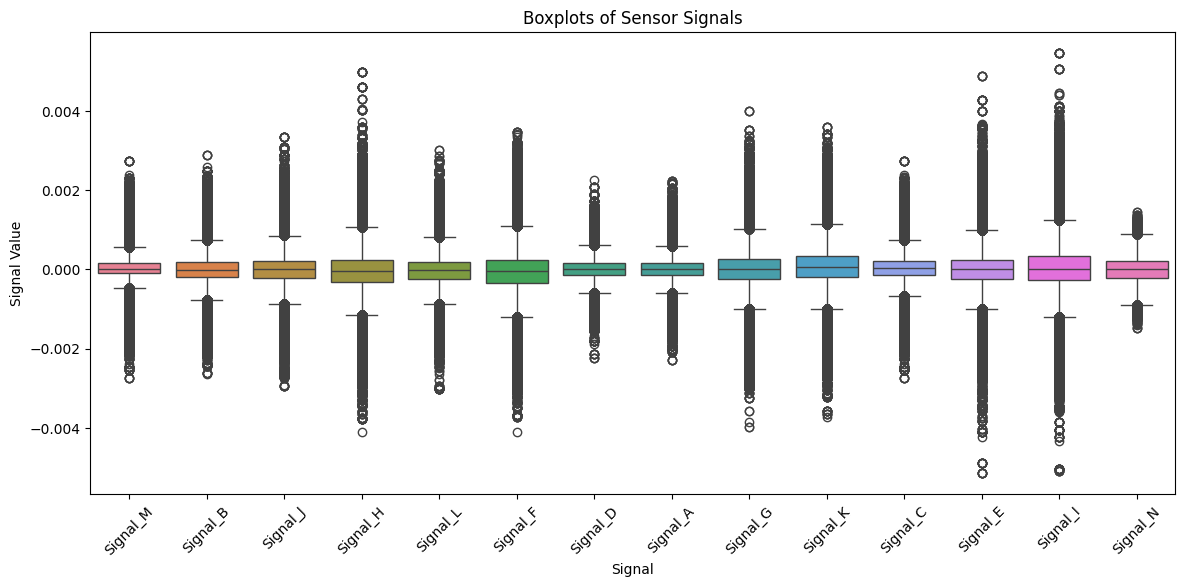

In [37]:
plt.figure(figsize=(14, 6))
sns.boxplot(data=data[signal_cols])
plt.title("Boxplots of Sensor Signals")
plt.xlabel("Signal")
plt.ylabel("Signal Value")
plt.xticks(rotation=45)
plt.show()

The boxplots show that some signals have extreme values. We keep these values because they may represent real movement peaks, not errors.

### Impute Missing Sensor Values

We fill missing sensor readings within each sample using nearby time steps.

In [38]:
data_clean = data.copy()
test_clean = test.copy()

data_clean = data_clean.sort_values(["Sample_ID", "Time_Step"])
test_clean = test_clean.sort_values(["Sample_ID", "Time_Step"])

data_clean[signal_cols] = (
    data_clean.groupby("Sample_ID")[signal_cols]
    .transform(lambda x: x.ffill().bfill())
)

test_clean[signal_cols] = (
    test_clean.groupby("Sample_ID")[signal_cols]
    .transform(lambda x: x.ffill().bfill())
)

data_clean[signal_cols] = data_clean[signal_cols].fillna(data_clean[signal_cols].median())
test_clean[signal_cols] = test_clean[signal_cols].fillna(test_clean[signal_cols].median())

print("Training missing values after imputation:", data_clean.isnull().sum().sum())
print("Test missing values after imputation:", test_clean.isnull().sum().sum())

Training missing values after imputation: 0
Test missing values after imputation: 0


After imputation, there are no missing values left in the sensor data.

## Exploratory Data Analysis

We explore the cleaned data before feature engineering and modelling.

### Target Class Distribution

We check if the six classes are balanced.

In [39]:
class_counts = train["class_label"].value_counts().sort_index()
class_percentages = (train["class_label"].value_counts(normalize=True).sort_index() * 100).round(2)

class_distribution = pd.DataFrame({
    "count": class_counts,
    "percentage": class_percentages
})

class_distribution

,count,percentage
class_label,,
1,380,13.61
2,377,13.50
3,432,15.47
4,489,17.51
5,549,19.66
6,566,20.26


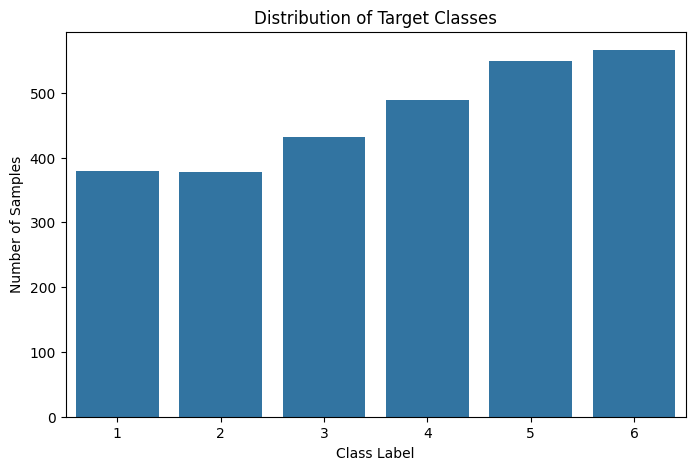

In [40]:
plt.figure(figsize=(8, 5))
sns.countplot(x="class_label", data=train)
plt.title("Distribution of Target Classes")
plt.xlabel("Class Label")
plt.ylabel("Number of Samples")
plt.show()

The classes are slightly imbalanced, so Macro-F1 is a good metric because it treats all classes fairly.

### Signal Summary Statistics

We summarise the sensor signals after cleaning.

In [41]:
data_clean[signal_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Signal_M,279300.0,2.802835e-05,0.000378,-0.002734,-0.000093,0.000000e+00,0.000166,0.002741
Signal_B,279300.0,-1.178688e-05,0.000429,-0.002647,-0.000203,-5.461130e-06,0.000179,0.002882
Signal_J,279300.0,-6.994578e-06,0.000474,-0.002936,-0.000223,-1.643272e-07,0.000209,0.003339
Signal_H,279300.0,-3.674430e-05,0.000598,-0.004118,-0.000315,-2.862267e-05,0.000242,0.004984
Signal_L,279300.0,-2.648277e-05,0.000448,-0.003027,-0.000239,-2.287090e-05,0.000179,0.003027
Signal_F,279300.0,-4.755580e-05,0.000618,-0.004101,-0.000338,-3.803613e-05,0.000235,0.003471
Signal_D,279300.0,1.158635e-05,0.000325,-0.002237,-0.000140,7.267517e-06,0.000162,0.002253
Signal_A,279300.0,1.439220e-06,0.000326,-0.002294,-0.000147,4.476931e-07,0.000151,0.002226
Signal_G,279300.0,1.487888e-05,0.000568,-0.003975,-0.000241,6.021711e-06,0.000268,0.003995
Signal_K,279300.0,5.857151e-05,0.000588,-0.003732,-0.000203,4.930219e-05,0.000333,0.003603


In [42]:
signal_summary = data_clean[signal_cols].agg(["mean", "std", "min", "max"]).T
signal_summary

,mean,std,min,max
Signal_M,2.802835e-05,0.000378,-0.002734,0.002741
Signal_B,-1.178688e-05,0.000429,-0.002647,0.002882
Signal_J,-6.994578e-06,0.000474,-0.002936,0.003339
Signal_H,-3.674430e-05,0.000598,-0.004118,0.004984
Signal_L,-2.648277e-05,0.000448,-0.003027,0.003027
Signal_F,-4.755580e-05,0.000618,-0.004101,0.003471
Signal_D,1.158635e-05,0.000325,-0.002237,0.002253
Signal_A,1.439220e-06,0.000326,-0.002294,0.002226
Signal_G,1.487888e-05,0.000568,-0.003975,0.003995
Signal_K,5.857151e-05,0.000588,-0.003732,0.003603


The signals are centred close to zero, but some signals have wider ranges than others.

### Temporal Signal Plot

We plot signals across time for one sample.

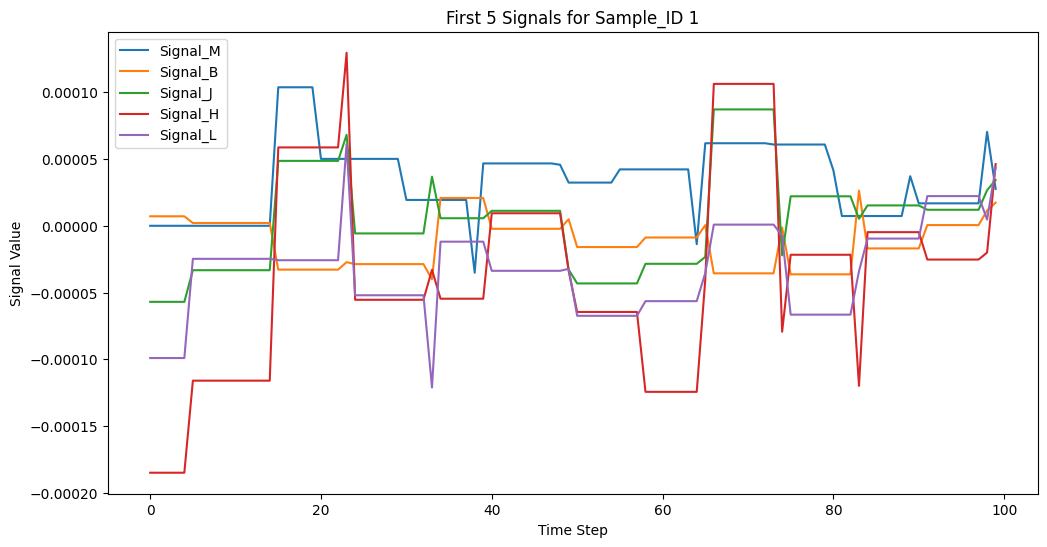

In [43]:
sample_id = data_clean["Sample_ID"].iloc[0]

one_sample = data_clean[data_clean["Sample_ID"] == sample_id]

plt.figure(figsize=(12, 6))

for col in signal_cols[:5]:
    plt.plot(one_sample["Time_Step"], one_sample[col], label=col)

plt.title(f"First 5 Signals for Sample_ID {sample_id}")
plt.xlabel("Time Step")
plt.ylabel("Signal Value")
plt.legend()
plt.show()

The signals change over time, so the time-step structure contains useful information.

### Signal Pattern Across Classes

We compare one signal across different classes.

In [44]:
merged_for_plot = data_clean.merge(train, on="Sample_ID", how="left")

example_ids = (
    merged_for_plot[["Sample_ID", "class_label"]]
    .drop_duplicates()
    .groupby("class_label")
    .head(1)
)

example_ids

,Sample_ID,class_label
0,1,1
1200,13,2
2400,25,3
3900,40,4
5400,55,5
6900,70,6


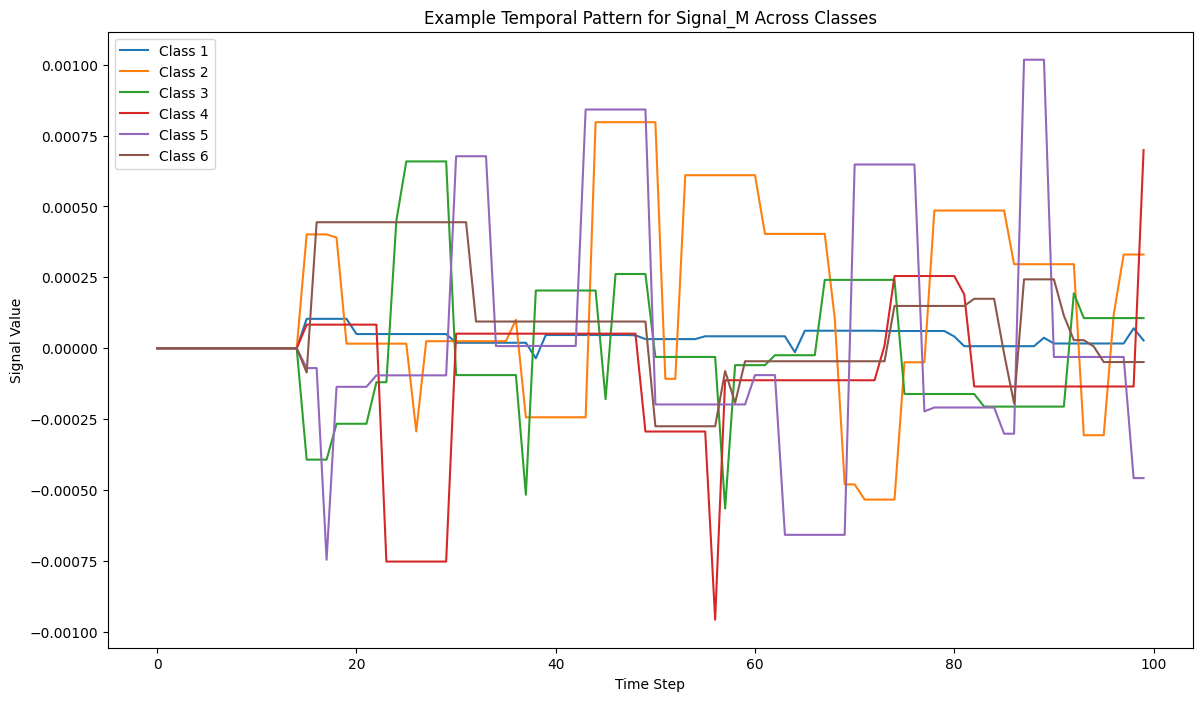

In [45]:
plt.figure(figsize=(14, 8))

for class_label in sorted(train["class_label"].unique()):
    sample_id = example_ids[example_ids["class_label"] == class_label]["Sample_ID"].iloc[0]
    sample = merged_for_plot[merged_for_plot["Sample_ID"] == sample_id]
    plt.plot(sample["Time_Step"], sample[signal_cols[0]], label=f"Class {class_label}")

plt.title(f"Example Temporal Pattern for {signal_cols[0]} Across Classes")
plt.xlabel("Time Step")
plt.ylabel("Signal Value")
plt.legend()
plt.show()

Different classes show different signal patterns, which supports using temporal feature engineering.

### Correlation Between Signals

We check whether some signals are strongly related.

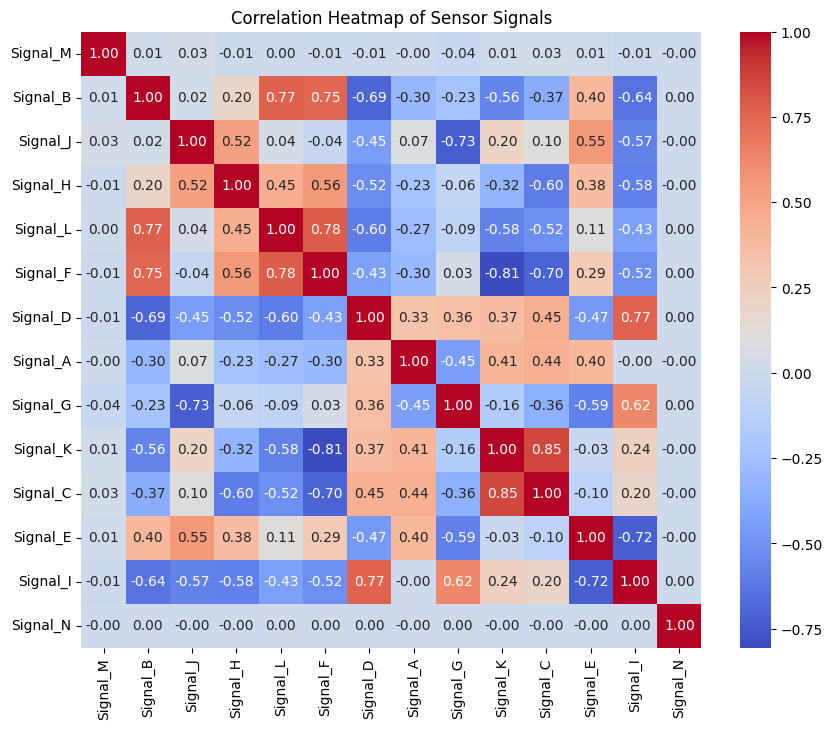

In [46]:
corr_matrix = data_clean[signal_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap of Sensor Signals")
plt.show()

In [47]:
corr_pairs = corr_matrix.abs().unstack().sort_values(ascending=False)

# Remove self-correlations
corr_pairs = corr_pairs[corr_pairs < 1]

# Remove duplicate pairs
corr_pairs = corr_pairs.drop_duplicates()

corr_pairs.head(15)

Signal_C  Signal_K    0.852761
Signal_F  Signal_K    0.805035
          Signal_L    0.781479
Signal_B  Signal_L    0.767405
Signal_D  Signal_I    0.767099
Signal_B  Signal_F    0.752619
Signal_G  Signal_J    0.729998
Signal_E  Signal_I    0.724122
Signal_C  Signal_F    0.702730
Signal_B  Signal_D    0.693046
Signal_I  Signal_B    0.639734
          Signal_G    0.623252
Signal_H  Signal_C    0.603612
Signal_D  Signal_L    0.598584
Signal_E  Signal_G    0.585870
dtype: float64

Some signals are strongly correlated, which suggests redundancy or signal entanglement.

## Feature Engineering

We convert each 100-step sample into one row of features.

### Base Statistical and Temporal Features

We extract summary and time-based features from each signal.

In [48]:
def extract_features(df):
    df = df.copy()
    df = df.sort_values(["Sample_ID", "Time_Step"])

    signal_cols = [col for col in df.columns if col.startswith("Signal")]

    # Statistical features
    agg_features = df.groupby("Sample_ID")[signal_cols].agg([
        "mean",
        "std",
        "min",
        "max",
        "median",
        skew,
        kurtosis
    ])

    agg_features.columns = [
        f"{signal}_{stat}" for signal, stat in agg_features.columns
    ]

    # Range
    range_features = (
        df.groupby("Sample_ID")[signal_cols].max()
        - df.groupby("Sample_ID")[signal_cols].min()
    )
    range_features.columns = [f"{col}_range" for col in range_features.columns]

    # IQR
    q75 = df.groupby("Sample_ID")[signal_cols].quantile(0.75)
    q25 = df.groupby("Sample_ID")[signal_cols].quantile(0.25)
    iqr_features = q75 - q25
    iqr_features.columns = [f"{col}_iqr" for col in iqr_features.columns]

    # First and last values
    first_features = df.groupby("Sample_ID")[signal_cols].first()
    first_features.columns = [f"{col}_first" for col in first_features.columns]

    last_features = df.groupby("Sample_ID")[signal_cols].last()
    last_features.columns = [f"{col}_last" for col in last_features.columns]

    # Change from first to last
    change_features = last_features.copy()
    change_features.columns = [col.replace("_last", "_change") for col in change_features.columns]
    change_features.iloc[:, :] = last_features.values - first_features.values

    # Energy
    energy_features = df.copy()
    energy_features[signal_cols] = energy_features[signal_cols] ** 2
    energy_features = energy_features.groupby("Sample_ID")[signal_cols].sum()
    energy_features.columns = [f"{col}_energy" for col in energy_features.columns]

    # Difference features
    diff_df = df.copy()
    diff_df[signal_cols] = diff_df.groupby("Sample_ID")[signal_cols].diff()

    diff_mean = diff_df.groupby("Sample_ID")[signal_cols].mean()
    diff_mean.columns = [f"{col}_diff_mean" for col in diff_mean.columns]

    diff_std = diff_df.groupby("Sample_ID")[signal_cols].std()
    diff_std.columns = [f"{col}_diff_std" for col in diff_std.columns]

    diff_abs_mean = diff_df.copy()
    diff_abs_mean[signal_cols] = diff_abs_mean[signal_cols].abs()
    diff_abs_mean = diff_abs_mean.groupby("Sample_ID")[signal_cols].mean()
    diff_abs_mean.columns = [f"{col}_diff_abs_mean" for col in diff_abs_mean.columns]

    diff_abs_max = diff_df.copy()
    diff_abs_max[signal_cols] = diff_abs_max[signal_cols].abs()
    diff_abs_max = diff_abs_max.groupby("Sample_ID")[signal_cols].max()
    diff_abs_max.columns = [f"{col}_diff_abs_max" for col in diff_abs_max.columns]

    features = pd.concat([
        agg_features,
        range_features,
        iqr_features,
        first_features,
        last_features,
        change_features,
        energy_features,
        diff_mean,
        diff_std,
        diff_abs_mean,
        diff_abs_max
    ], axis=1)

    features = features.reset_index()

    return features

In [49]:
base_train_features = extract_features(data_clean)

print("Base train feature shape:", base_train_features.shape)
base_train_features.head()

Base train feature shape: (2793, 239)


,Sample_ID,Signal_M_mean,Signal_M_std,Signal_M_min,Signal_M_max,Signal_M_median,Signal_M_skew,Signal_M_kurtosis,Signal_B_mean,Signal_B_std,Signal_B_min,Signal_B_max,Signal_B_median,Signal_B_skew,Signal_B_kurtosis,Signal_J_mean,Signal_J_std,Signal_J_min,Signal_J_max,Signal_J_median,Signal_J_skew,Signal_J_kurtosis,Signal_H_mean,Signal_H_std,Signal_H_min,Signal_H_max,Signal_H_median,Signal_H_skew,Signal_H_kurtosis,Signal_L_mean,Signal_L_std,Signal_L_min,Signal_L_max,Signal_L_median,Signal_L_skew,Signal_L_kurtosis,Signal_F_mean,Signal_F_std,Signal_F_min,Signal_F_max,Signal_F_median,Signal_F_skew,Signal_F_kurtosis,Signal_D_mean,Signal_D_std,Signal_D_min,Signal_D_max,Signal_D_median,Signal_D_skew,Signal_D_kurtosis,...,Signal_D_diff_mean,Signal_A_diff_mean,Signal_G_diff_mean,Signal_K_diff_mean,Signal_C_diff_mean,Signal_E_diff_mean,Signal_I_diff_mean,Signal_N_diff_mean,Signal_M_diff_std,Signal_B_diff_std,Signal_J_diff_std,Signal_H_diff_std,Signal_L_diff_std,Signal_F_diff_std,Signal_D_diff_std,Signal_A_diff_std,Signal_G_diff_std,Signal_K_diff_std,Signal_C_diff_std,Signal_E_diff_std,Signal_I_diff_std,Signal_N_diff_std,Signal_M_diff_abs_mean,Signal_B_diff_abs_mean,Signal_J_diff_abs_mean,Signal_H_diff_abs_mean,Signal_L_diff_abs_mean,Signal_F_diff_abs_mean,Signal_D_diff_abs_mean,Signal_A_diff_abs_mean,Signal_G_diff_abs_mean,Signal_K_diff_abs_mean,Signal_C_diff_abs_mean,Signal_E_diff_abs_mean,Signal_I_diff_abs_mean,Signal_N_diff_abs_mean,Signal_M_diff_abs_max,Signal_B_diff_abs_max,Signal_J_diff_abs_max,Signal_H_diff_abs_max,Signal_L_diff_abs_max,Signal_F_diff_abs_max,Signal_D_diff_abs_max,Signal_A_diff_abs_max,Signal_G_diff_abs_max,Signal_K_diff_abs_max,Signal_C_diff_abs_max,Signal_E_diff_abs_max,Signal_I_diff_abs_max,Signal_N_diff_abs_max
0,1,0.000035,0.000028,-0.000035,0.000104,0.000042,0.354932,0.135124,-1.248078e-05,0.000018,-0.000040,0.000026,-1.235468e-05,0.144311,-1.082446,4.682003e-06,0.000038,-0.000057,0.000087,0.000011,0.477346,-0.254345,-0.000034,0.000074,-0.000185,0.000130,-0.000029,0.143065,-0.293547,-0.000033,0.000033,-0.000121,0.000061,-0.000029,0.011461,0.089426,-0.000047,0.000048,-0.000137,0.000084,-0.000036,-0.439828,-0.274870,0.000010,0.000026,-0.000044,0.000044,0.000016,-0.412659,-1.098577,...,4.008680e-08,7.427244e-07,-9.383626e-07,-1.489083e-06,-1.077705e-06,8.820748e-07,-9.535054e-07,0.000007,0.000020,0.000013,0.000021,0.000043,0.000023,0.000028,0.000017,0.000016,0.000022,0.000022,0.000018,0.000026,0.000030,0.000505,0.000007,0.000004,0.000007,0.000015,0.000008,0.000010,0.000006,0.000006,0.000008,0.000008,0.000007,0.000009,0.000011,0.000393,0.000104,0.000063,0.000110,0.000186,0.000113,0.000126,0.000066,0.000081,0.000103,0.000088,0.000082,0.000114,0.000171,0.001385
1,2,0.000010,0.000024,-0.000031,0.000077,0.000009,0.687250,0.881553,-5.062734e-06,0.000022,-0.000046,0.000060,-4.658110e-06,0.021965,-0.388841,1.480371e-06,0.000041,-0.000061,0.000085,-0.000006,0.487286,-0.589497,-0.000019,0.000074,-0.000126,0.000119,-0.000021,0.137849,-0.830689,-0.000020,0.000036,-0.000086,0.000043,-0.000010,-0.245852,-0.728273,-0.000015,0.000065,-0.000142,0.000084,0.000010,-0.596042,-0.631181,0.000016,0.000017,-0.000039,0.000048,0.000017,-0.578348,1.011412,...,-8.073795e-08,-6.050908e-07,5.745434e-07,1.372277e-06,8.944319e-07,-9.976326e-07,9.119640e-07,0.000009,0.000016,0.000017,0.000025,0.000039,0.000017,0.000026,0.000015,0.000017,0.000021,0.000017,0.000017,0.000024,0.000026,0.000511,0.000005,0.000005,0.000008,0.000013,0.000006,0.000010,0.000005,0.000006,0.000007,0.000006,0.000006,0.000008,0.000009,0.000412,0.000082,0.000106,0.000146,0.000245,0.000081,0.000095,0.000086,0.000085,0.000118,0.000072,0.000082,0.000100,0.000139,0.001201
2,3,0.000013,0.000030,-0.000041,0.000079,0.000000,0.499349,-0.579467,-7.602384e-07,0.000026,-0.000045,0.000066,-1.128803e-06,0.535278,0.736375,7.753689e-07,0.000032,-0.000074,0.000044,0.000010,-0.205652,-1.325070,-0.000015,0.000056,-0.000147,0.000072,-0.000029,-0.237138,-0.776381,-0.000018,0.000036,-0.000127,0.00

The base features give one row per `Sample_ID`.

### Advanced Time-Series Features

We add shape, percentile, and frequency features.

In [50]:
def extract_extra_time_features(df):
    df = df.copy()
    df = df.sort_values(["Sample_ID", "Time_Step"])

    signal_cols = [col for col in df.columns if col.startswith("Signal")]
    feature_rows = []

    for sample_id, group in df.groupby("Sample_ID"):
        row = {"Sample_ID": sample_id}

        for col in signal_cols:
            values = group[col].values

            # Shape features
            row[f"{col}_abs_max"] = np.max(np.abs(values))
            row[f"{col}_mean_abs"] = np.mean(np.abs(values))
            row[f"{col}_rms"] = np.sqrt(np.mean(values ** 2))
            row[f"{col}_zero_crossings"] = np.sum(np.diff(np.sign(values)) != 0)

            # Percentile features
            row[f"{col}_p05"] = np.percentile(values, 5)
            row[f"{col}_p10"] = np.percentile(values, 10)
            row[f"{col}_p90"] = np.percentile(values, 90)
            row[f"{col}_p95"] = np.percentile(values, 95)

            # Frequency features
            fft_values = np.abs(np.fft.rfft(values))
            row[f"{col}_fft_mean"] = np.mean(fft_values)
            row[f"{col}_fft_std"] = np.std(fft_values)
            row[f"{col}_fft_max"] = np.max(fft_values)
            row[f"{col}_fft_energy"] = np.sum(fft_values ** 2)
            row[f"{col}_dominant_freq"] = np.argmax(fft_values)

        feature_rows.append(row)

    return pd.DataFrame(feature_rows)

In [51]:
extra_train_features = extract_extra_time_features(data_clean)

train_features = base_train_features.merge(extra_train_features, on="Sample_ID", how="inner")

print("Base train feature shape:", base_train_features.shape)
print("Extra train feature shape:", extra_train_features.shape)
print("Final train feature shape:", train_features.shape)

train_features.head()

Base train feature shape: (2793, 239)
Extra train feature shape: (2793, 183)
Final train feature shape: (2793, 421)


,Sample_ID,Signal_M_mean,Signal_M_std,Signal_M_min,Signal_M_max,Signal_M_median,Signal_M_skew,Signal_M_kurtosis,Signal_B_mean,Signal_B_std,Signal_B_min,Signal_B_max,Signal_B_median,Signal_B_skew,Signal_B_kurtosis,Signal_J_mean,Signal_J_std,Signal_J_min,Signal_J_max,Signal_J_median,Signal_J_skew,Signal_J_kurtosis,Signal_H_mean,Signal_H_std,Signal_H_min,Signal_H_max,Signal_H_median,Signal_H_skew,Signal_H_kurtosis,Signal_L_mean,Signal_L_std,Signal_L_min,Signal_L_max,Signal_L_median,Signal_L_skew,Signal_L_kurtosis,Signal_F_mean,Signal_F_std,Signal_F_min,Signal_F_max,Signal_F_median,Signal_F_skew,Signal_F_kurtosis,Signal_D_mean,Signal_D_std,Signal_D_min,Signal_D_max,Signal_D_median,Signal_D_skew,Signal_D_kurtosis,...,Signal_C_rms,Signal_C_zero_crossings,Signal_C_p05,Signal_C_p10,Signal_C_p90,Signal_C_p95,Signal_C_fft_mean,Signal_C_fft_std,Signal_C_fft_max,Signal_C_fft_energy,Signal_C_dominant_freq,Signal_E_abs_max,Signal_E_mean_abs,Signal_E_rms,Signal_E_zero_crossings,Signal_E_p05,Signal_E_p10,Signal_E_p90,Signal_E_p95,Signal_E_fft_mean,Signal_E_fft_std,Signal_E_fft_max,Signal_E_fft_energy,Signal_E_dominant_freq,Signal_I_abs_max,Signal_I_mean_abs,Signal_I_rms,Signal_I_zero_crossings,Signal_I_p05,Signal_I_p10,Signal_I_p90,Signal_I_p95,Signal_I_fft_mean,Signal_I_fft_std,Signal_I_fft_max,Signal_I_fft_energy,Signal_I_dominant_freq,Signal_N_abs_max,Signal_N_mean_abs,Signal_N_rms,Signal_N_zero_crossings,Signal_N_p05,Signal_N_p10,Signal_N_p90,Signal_N_p95,Signal_N_fft_mean,Signal_N_fft_std,Signal_N_fft_max,Signal_N_fft_energy,Signal_N_dominant_freq
0,1,0.000035,0.000028,-0.000035,0.000104,0.000042,0.354932,0.135124,-1.248078e-05,0.000018,-0.000040,0.000026,-1.235468e-05,0.144311,-1.082446,4.682003e-06,0.000038,-0.000057,0.000087,0.000011,0.477346,-0.254345,-0.000034,0.000074,-0.000185,0.000130,-0.000029,0.143065,-0.293547,-0.000033,0.000033,-0.000121,0.000061,-0.000029,0.011461,0.089426,-0.000047,0.000048,-0.000137,0.000084,-0.000036,-0.439828,-0.274870,0.000010,0.000026,-0.000044,0.000044,0.000016,-0.412659,-1.098577,...,0.000045,7,-0.000014,0.000006,0.000062,0.000072,0.000263,0.000501,0.003532,0.000016,0,0.000072,0.000040,0.000047,11,-0.000067,-0.000061,0.000068,0.000068,0.000285,0.000367,0.002387,0.000011,4,0.000098,0.000047,0.000054,9,-0.000098,-0.000037,0.000070,0.000086,0.000349,0.000437,0.002229,0.000016,4,0.000959,0.000268,0.000345,53,-0.000617,-0.000378,0.000422,0.000520,0.003042,0.001599,0.009545,0.000602,26
1,2,0.000010,0.000024,-0.000031,0.000077,0.000009,0.687250,0.881553,-5.062734e-06,0.000022,-0.000046,0.000060,-4.658110e-06,0.021965,-0.388841,1.480371e-06,0.000041,-0.000061,0.000085,-0.000006,0.487286,-0.589497,-0.000019,0.000074,-0.000126,0.000119,-0.000021,0.137849,-0.830689,-0.000020,0.000036,-0.000086,0.000043,-0.000010,-0.245852,-0.728273,-0.000015,0.000065,-0.000142,0.000084,0.000010,-0.596042,-0.631181,0.000016,0.000017,-0.000039,0.000048,0.000017,-0.578348,1.011412,...,0.000039,5,-0.000031,-0.000017,0.000078,0.000086,0.000250,0.000356,0.002089,0.000010,0,0.000097,0.000036,0.000047,9,-0.000042,-0.000027,0.000072,0.000097,0.000298,0.000379,0.001798,0.000012,3,0.000089,0.000043,0.000050,7,-0.000071,-0.000044,0.000070,0.000089,0.000334,0.000402,0.001731,0.000014,3,0.001061,0.000305,0.000367,43,-0.000572,-0.000514,0.000468,0.000595,0.003288,0.001605,0.007517,0.000683,23
2,3,0.000013,0.000030,-0.000041,0.000079,0.000000,0.499349,-0.579467,-7.602384e-07,0.000026,-0.000045,0.000066,-1.128803e-06,0.535278,0.736375,7.753689e-07,0.000032,-0.000074,0.000044,0.000010,-0.205652,-1.325070,-0.000015,0.000056,-0.000147,0.000072,-0.000029,-0.237138,-0.776381,-0.000018,0.000036,-0.000127,0.000056,-0.000029,-0.160524,1.287525,-0.000020,0.000054,-0.000158,0.000036,0.000010,-0.861160,-0.381436,0.000004,0.000029,-0.000051,0.000057,-0.000001,-0.250088,-0.402929,...,0.000034,9,-0.000025,-0.000024,0.000055,0.000073,0.000244,0.000285,0.001659,0.000007,0,0.000085,0.000031,0.000038,13,-0.000050,-0.000042,0.000052,0.000085,0.000289,0.000247,0.0

In [52]:
print("Missing values in train features:", train_features.isnull().sum().sum())
print("Unique Sample_IDs:", train_features["Sample_ID"].nunique())

Missing values in train features: 0
Unique Sample_IDs: 2793


The final engineered dataset has one row per sample with base and advanced features.

## Preparing the Modelling Dataset

We merge the engineered features with the labels.

In [53]:
df_model = train_features.merge(train, on="Sample_ID", how="inner")

print("Model dataset shape:", df_model.shape)
df_model.head()

Model dataset shape: (2793, 422)


,Sample_ID,Signal_M_mean,Signal_M_std,Signal_M_min,Signal_M_max,Signal_M_median,Signal_M_skew,Signal_M_kurtosis,Signal_B_mean,Signal_B_std,Signal_B_min,Signal_B_max,Signal_B_median,Signal_B_skew,Signal_B_kurtosis,Signal_J_mean,Signal_J_std,Signal_J_min,Signal_J_max,Signal_J_median,Signal_J_skew,Signal_J_kurtosis,Signal_H_mean,Signal_H_std,Signal_H_min,Signal_H_max,Signal_H_median,Signal_H_skew,Signal_H_kurtosis,Signal_L_mean,Signal_L_std,Signal_L_min,Signal_L_max,Signal_L_median,Signal_L_skew,Signal_L_kurtosis,Signal_F_mean,Signal_F_std,Signal_F_min,Signal_F_max,Signal_F_median,Signal_F_skew,Signal_F_kurtosis,Signal_D_mean,Signal_D_std,Signal_D_min,Signal_D_max,Signal_D_median,Signal_D_skew,Signal_D_kurtosis,...,Signal_C_zero_crossings,Signal_C_p05,Signal_C_p10,Signal_C_p90,Signal_C_p95,Signal_C_fft_mean,Signal_C_fft_std,Signal_C_fft_max,Signal_C_fft_energy,Signal_C_dominant_freq,Signal_E_abs_max,Signal_E_mean_abs,Signal_E_rms,Signal_E_zero_crossings,Signal_E_p05,Signal_E_p10,Signal_E_p90,Signal_E_p95,Signal_E_fft_mean,Signal_E_fft_std,Signal_E_fft_max,Signal_E_fft_energy,Signal_E_dominant_freq,Signal_I_abs_max,Signal_I_mean_abs,Signal_I_rms,Signal_I_zero_crossings,Signal_I_p05,Signal_I_p10,Signal_I_p90,Signal_I_p95,Signal_I_fft_mean,Signal_I_fft_std,Signal_I_fft_max,Signal_I_fft_energy,Signal_I_dominant_freq,Signal_N_abs_max,Signal_N_mean_abs,Signal_N_rms,Signal_N_zero_crossings,Signal_N_p05,Signal_N_p10,Signal_N_p90,Signal_N_p95,Signal_N_fft_mean,Signal_N_fft_std,Signal_N_fft_max,Signal_N_fft_energy,Signal_N_dominant_freq,class_label
0,1,0.000035,0.000028,-0.000035,0.000104,0.000042,0.354932,0.135124,-1.248078e-05,0.000018,-0.000040,0.000026,-1.235468e-05,0.144311,-1.082446,4.682003e-06,0.000038,-0.000057,0.000087,0.000011,0.477346,-0.254345,-0.000034,0.000074,-0.000185,0.000130,-0.000029,0.143065,-0.293547,-0.000033,0.000033,-0.000121,0.000061,-0.000029,0.011461,0.089426,-0.000047,0.000048,-0.000137,0.000084,-0.000036,-0.439828,-0.274870,0.000010,0.000026,-0.000044,0.000044,0.000016,-0.412659,-1.098577,...,7,-0.000014,0.000006,0.000062,0.000072,0.000263,0.000501,0.003532,0.000016,0,0.000072,0.000040,0.000047,11,-0.000067,-0.000061,0.000068,0.000068,0.000285,0.000367,0.002387,0.000011,4,0.000098,0.000047,0.000054,9,-0.000098,-0.000037,0.000070,0.000086,0.000349,0.000437,0.002229,0.000016,4,0.000959,0.000268,0.000345,53,-0.000617,-0.000378,0.000422,0.000520,0.003042,0.001599,0.009545,0.000602,26,1
1,2,0.000010,0.000024,-0.000031,0.000077,0.000009,0.687250,0.881553,-5.062734e-06,0.000022,-0.000046,0.000060,-4.658110e-06,0.021965,-0.388841,1.480371e-06,0.000041,-0.000061,0.000085,-0.000006,0.487286,-0.589497,-0.000019,0.000074,-0.000126,0.000119,-0.000021,0.137849,-0.830689,-0.000020,0.000036,-0.000086,0.000043,-0.000010,-0.245852,-0.728273,-0.000015,0.000065,-0.000142,0.000084,0.000010,-0.596042,-0.631181,0.000016,0.000017,-0.000039,0.000048,0.000017,-0.578348,1.011412,...,5,-0.000031,-0.000017,0.000078,0.000086,0.000250,0.000356,0.002089,0.000010,0,0.000097,0.000036,0.000047,9,-0.000042,-0.000027,0.000072,0.000097,0.000298,0.000379,0.001798,0.000012,3,0.000089,0.000043,0.000050,7,-0.000071,-0.000044,0.000070,0.000089,0.000334,0.000402,0.001731,0.000014,3,0.001061,0.000305,0.000367,43,-0.000572,-0.000514,0.000468,0.000595,0.003288,0.001605,0.007517,0.000683,23,1
2,3,0.000013,0.000030,-0.000041,0.000079,0.000000,0.499349,-0.579467,-7.602384e-07,0.000026,-0.000045,0.000066,-1.128803e-06,0.535278,0.736375,7.753689e-07,0.000032,-0.000074,0.000044,0.000010,-0.205652,-1.325070,-0.000015,0.000056,-0.000147,0.000072,-0.000029,-0.237138,-0.776381,-0.000018,0.000036,-0.000127,0.000056,-0.000029,-0.160524,1.287525,-0.000020,0.000054,-0.000158,0.000036,0.000010,-0.861160,-0.381436,0.000004,0.000029,-0.000051,0.000057,-0.000001,-0.250088,-0.402929,...,9,-0.000025,-0.000024,0.000055,0.000073,0.000244,0.000285,0.001659,0.000007,0,0.000085,0.000031,0.000038,13,-0.000050,-0.000042,0.000052,0.000085,0.000289,0.000247,0.001175,0.000007,3,0.00007

In [54]:
print("Feature samples:", train_features["Sample_ID"].nunique())
print("Label samples:", train["Sample_ID"].nunique())
print("Merged samples:", df_model["Sample_ID"].nunique())

Feature samples: 2793
Label samples: 2793
Merged samples: 2793


In [55]:
X = df_model.drop(columns=["Sample_ID", "class_label"])
y = df_model["class_label"].astype(int)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Missing values in X:", X.isnull().sum().sum())
print("Missing values in y:", y.isnull().sum())

X shape: (2793, 420)
y shape: (2793,)
Missing values in X: 0
Missing values in y: 0


The features and labels merged correctly, with no missing values in `X` or `y`.

## Dimensionality Reduction

We use PCA to reduce feature redundancy and inspect whether the engineered features contain lower-dimensional structure.

In [56]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

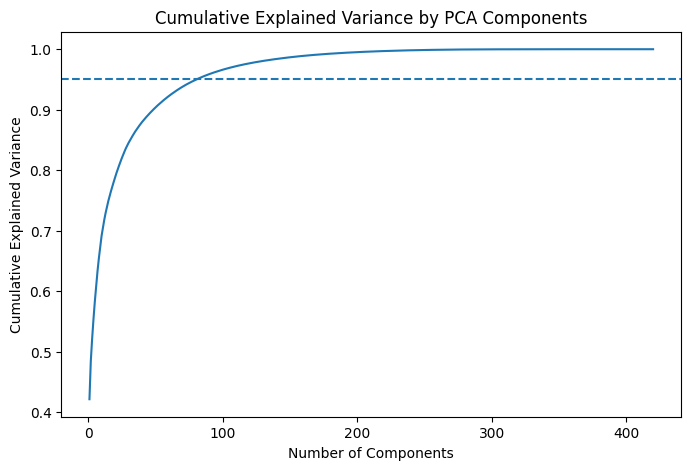

In [57]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA()
X_pca_full = pca.fit_transform(X_scaled)

explained_variance = np.cumsum(pca.explained_variance_ratio_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(explained_variance) + 1), explained_variance)
plt.axhline(y=0.95, linestyle="--")
plt.title("Cumulative Explained Variance by PCA Components")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.show()

In [58]:
n_components_95 = np.argmax(explained_variance >= 0.95) + 1

print("Number of components needed for 95% variance:", n_components_95)

Number of components needed for 95% variance: 81


In [59]:
pca_95 = PCA(n_components=0.95, random_state=RANDOM_STATE)
X_pca = pca_95.fit_transform(X_scaled)

print("Original X shape:", X.shape)
print("PCA X shape:", X_pca.shape)

Original X shape: (2793, 420)
PCA X shape: (2793, 81)


## Local Validation Strategy

We split the data into training and validation sets.

In [60]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("y_train shape:", y_train.shape)
print("y_val shape:", y_val.shape)

X_train shape: (2234, 420)
X_val shape: (559, 420)
y_train shape: (2234,)
y_val shape: (559,)


In [61]:
print("Training class distribution:")
display(y_train.value_counts(normalize=True).sort_index())

print("Validation class distribution:")
display(y_val.value_counts(normalize=True).sort_index())

Training class distribution:


,proportion
class_label,
1,0.136079
2,0.135184
3,0.154432
4,0.175022
5,0.196509
6,0.202775


Validation class distribution:


,proportion
class_label,
1,0.135957
2,0.134168
3,0.155635
4,0.175313
5,0.196780
6,0.202147


Stratification keeps the class distribution similar in both sets.

## Model Training and Evaluation

We train several models and compare them using Macro-F1.

In [62]:
model_scores = []

### Random Forest Baseline

We start with Random Forest as a baseline model.

In [ ]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=RANDOM_STATE,
    class_weight="balanced",
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_preds = rf_model.predict(X_val)

rf_f1 = f1_score(y_val, rf_preds, average="macro")

model_scores.append({
    "Model": "Random Forest",
    "Validation Macro-F1": rf_f1
})

print("Random Forest Macro-F1:", rf_f1)
print(classification_report(y_val, rf_preds))

Random Forest Macro-F1: 0.7388245847218817
              precision    recall  f1-score   support

           1       0.97      0.99      0.98        76
           2       0.80      0.63      0.70        75
           3       0.68      0.57      0.62        87
           4       0.67      0.73      0.70        98
           5       0.67      0.80      0.73       110
           6       0.70      0.69      0.69       113

    accuracy                           0.73       559
   macro avg       0.75      0.74      0.74       559
weighted avg       0.74      0.73      0.73       559



Random Forest gives a baseline Macro-F1 of about 0.738.

### Extra Trees with PCA

We test whether dimensionality reduction improves performance.

In [ ]:
X_train_pca, X_val_pca, y_train_pca, y_val_pca = train_test_split(
    X_pca,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

pca_et_model = ExtraTreesClassifier(
    n_estimators=500,
    max_features="sqrt",
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

pca_et_model.fit(X_train_pca, y_train_pca)

pca_et_preds = pca_et_model.predict(X_val_pca)

pca_et_f1 = f1_score(y_val_pca, pca_et_preds, average="macro")

model_scores.append({
    "Model": "Extra Trees with PCA",
    "Validation Macro-F1": pca_et_f1
})

print("Extra Trees with PCA Macro-F1:", pca_et_f1)
print(classification_report(y_val_pca, pca_et_preds))

Extra Trees with PCA Macro-F1: 0.7356011541384558
              precision    recall  f1-score   support

           1       0.90      0.99      0.94        76
           2       0.76      0.55      0.64        75
           3       0.75      0.51      0.60        87
           4       0.74      0.82      0.78        98
           5       0.66      0.84      0.74       110
           6       0.71      0.73      0.72       113

    accuracy                           0.74       559
   macro avg       0.75      0.74      0.74       559
weighted avg       0.74      0.74      0.73       559



### Extra Trees Classifier

We test Extra Trees as another tree-based ensemble model.

In [ ]:
et_model = ExtraTreesClassifier(
    n_estimators=500,
    max_features="sqrt",
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

et_model.fit(X_train, y_train)

et_preds = et_model.predict(X_val)

et_f1 = f1_score(y_val, et_preds, average="macro")

model_scores.append({
    "Model": "Extra Trees",
    "Validation Macro-F1": et_f1
})

print("Extra Trees Macro-F1:", et_f1)
print(classification_report(y_val, et_preds))

Extra Trees Macro-F1: 0.7600126928963146
              precision    recall  f1-score   support

           1       0.97      0.99      0.98        76
           2       0.81      0.64      0.72        75
           3       0.74      0.63      0.68        87
           4       0.66      0.77      0.71        98
           5       0.70      0.85      0.77       110
           6       0.74      0.67      0.70       113

    accuracy                           0.75       559
   macro avg       0.77      0.76      0.76       559
weighted avg       0.76      0.75      0.75       559



Extra Trees improves the Macro-F1 to about 0.760, so it performs better than the baseline. Extra Trees improves over the PCA version, so the full engineered features work better than the reduced PCA features.

### HistGradientBoosting Classifier

We test a boosting model because it can learn stronger non-linear patterns.

In [ ]:
hgb_model = HistGradientBoostingClassifier(
    max_iter=500,
    learning_rate=0.03,
    max_leaf_nodes=31,
    l2_regularization=0.01,
    random_state=RANDOM_STATE
)

hgb_model.fit(X_train, y_train)

hgb_preds = hgb_model.predict(X_val)

hgb_f1 = f1_score(y_val, hgb_preds, average="macro")

model_scores.append({
    "Model": "HistGradientBoosting",
    "Validation Macro-F1": hgb_f1
})

print("HistGradientBoosting Macro-F1:", hgb_f1)
print(classification_report(y_val, hgb_preds))

HistGradientBoosting Macro-F1: 0.7576531414928
              precision    recall  f1-score   support

           1       0.97      0.99      0.98        76
           2       0.75      0.68      0.71        75
           3       0.70      0.55      0.62        87
           4       0.75      0.79      0.77        98
           5       0.69      0.80      0.74       110
           6       0.72      0.73      0.73       113

    accuracy                           0.75       559
   macro avg       0.76      0.76      0.76       559
weighted avg       0.75      0.75      0.75       559



HistGradientBoosting performs close to Extra Trees, but Extra Trees is still slightly better on this split.

### SVM Classifier

We test SVM with scaling because it is sensitive to feature scale.

In [ ]:
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC(
        kernel="rbf",
        C=10,
        gamma="scale",
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

svm_model.fit(X_train, y_train)

svm_preds = svm_model.predict(X_val)

svm_f1 = f1_score(y_val, svm_preds, average="macro")

model_scores.append({
    "Model": "SVM",
    "Validation Macro-F1": svm_f1
})

print("SVM Macro-F1:", svm_f1)
print(classification_report(y_val, svm_preds))

SVM Macro-F1: 0.7367874964481042
              precision    recall  f1-score   support

           1       0.94      0.97      0.95        76
           2       0.70      0.72      0.71        75
           3       0.60      0.59      0.59        87
           4       0.78      0.77      0.77        98
           5       0.68      0.63      0.65       110
           6       0.72      0.76      0.74       113

    accuracy                           0.73       559
   macro avg       0.74      0.74      0.74       559
weighted avg       0.73      0.73      0.73       559



SVM did not improve the score, so the tree-based models are performing better for these engineered features.

### More Complex Boosting Models

We test XGBoost and LightGBM because boosting models often perform well on tabular engineered features.

In [ ]:
!pip install xgboost lightgbm -q

In [ ]:
from xgboost import XGBClassifier

# XGBoost needs labels from 0 to 5
y_train_xgb = y_train - 1
y_val_xgb = y_val - 1

xgb_model = XGBClassifier(
    n_estimators=800,
    learning_rate=0.03,
    max_depth=4,
    subsample=0.9,
    colsample_bytree=0.9,
    objective="multi:softmax",
    num_class=6,
    eval_metric="mlogloss",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train_xgb)

xgb_preds_zero = xgb_model.predict(X_val)
xgb_preds = xgb_preds_zero + 1

xgb_f1 = f1_score(y_val, xgb_preds, average="macro")

model_scores.append({
    "Model": "XGBoost",
    "Validation Macro-F1": xgb_f1
})

print("XGBoost Macro-F1:", xgb_f1)
print(classification_report(y_val, xgb_preds))

XGBoost Macro-F1: 0.7753189373109061
              precision    recall  f1-score   support

           1       0.97      0.99      0.98        76
           2       0.83      0.69      0.75        75
           3       0.74      0.57      0.65        87
           4       0.77      0.82      0.79        98
           5       0.70      0.77      0.73       110
           6       0.71      0.79      0.75       113

    accuracy                           0.77       559
   macro avg       0.79      0.77      0.78       559
weighted avg       0.77      0.77      0.77       559



XGBoost gives the best score so far, improving the validation Macro-F1 to about 0.775.

### LightGBM

We test LightGBM as another strong boosting model.

In [ ]:
from lightgbm import LGBMClassifier

lgbm_model = LGBMClassifier(
    n_estimators=1000,
    learning_rate=0.03,
    num_leaves=31,
    max_depth=-1,
    subsample=0.9,
    colsample_bytree=0.9,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=-1,
    force_col_wise=True
)

lgbm_model.fit(X_train, y_train)

lgbm_preds = lgbm_model.predict(X_val)

lgbm_f1 = f1_score(y_val, lgbm_preds, average="macro")

model_scores.append({
    "Model": "LightGBM",
    "Validation Macro-F1": lgbm_f1
})

print("LightGBM Macro-F1:", lgbm_f1)
print(classification_report(y_val, lgbm_preds))

LightGBM Macro-F1: 0.7719100245783032
              precision    recall  f1-score   support

           1       0.96      1.00      0.98        76
           2       0.78      0.69      0.73        75
           3       0.71      0.59      0.64        87
           4       0.76      0.79      0.77        98
           5       0.72      0.81      0.76       110
           6       0.73      0.75      0.74       113

    accuracy                           0.77       559
   macro avg       0.78      0.77      0.77       559
weighted avg       0.77      0.77      0.77       559



LightGBM performs well, but XGBoost is still slightly better on this validation split.

### LSTM Classifier

We test an LSTM because the original data is sequential.

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import to_categorical

In [ ]:
def make_sequence_dataset(sensor_df, labels_df=None):
    sensor_df = sensor_df.copy()
    sensor_df = sensor_df.sort_values(["Sample_ID", "Time_Step"])

    signal_cols = [col for col in sensor_df.columns if col.startswith("Signal")]
    sample_ids = sorted(sensor_df["Sample_ID"].unique())

    X_seq = []

    for sample_id in sample_ids:
        sample = sensor_df[sensor_df["Sample_ID"] == sample_id]
        X_seq.append(sample[signal_cols].values)

    X_seq = np.array(X_seq)

    if labels_df is not None:
        labels_ordered = (
            pd.DataFrame({"Sample_ID": sample_ids})
            .merge(labels_df, on="Sample_ID", how="left")
        )
        y_seq = labels_ordered["class_label"].astype(int).values
        return X_seq, y_seq, sample_ids

    return X_seq, sample_ids

In [ ]:
X_seq, y_seq, seq_sample_ids = make_sequence_dataset(data_clean, train)

print("X_seq shape:", X_seq.shape)
print("y_seq shape:", y_seq.shape)

X_seq shape: (2793, 100, 14)
y_seq shape: (2793,)


In [ ]:
num_samples, num_timesteps, num_signals = X_seq.shape

seq_scaler = StandardScaler()

X_seq_2d = X_seq.reshape(-1, num_signals)
X_seq_scaled_2d = seq_scaler.fit_transform(X_seq_2d)
X_seq_scaled = X_seq_scaled_2d.reshape(num_samples, num_timesteps, num_signals)

print("Scaled sequence shape:", X_seq_scaled.shape)

Scaled sequence shape: (2793, 100, 14)


In [ ]:
y_seq_zero = y_seq - 1
y_seq_cat = to_categorical(y_seq_zero, num_classes=6)

X_seq_train, X_seq_val, y_seq_train, y_seq_val = train_test_split(
    X_seq_scaled,
    y_seq_cat,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_seq_zero
)

print("X_seq_train shape:", X_seq_train.shape)
print("X_seq_val shape:", X_seq_val.shape)

X_seq_train shape: (2234, 100, 14)
X_seq_val shape: (559, 100, 14)


In [ ]:
def build_lstm_model(seed=RANDOM_STATE):
    tf.random.set_seed(seed)
    np.random.seed(seed)

    model = Sequential([
        LSTM(64, return_sequences=True, input_shape=(100, 14)),
        Dropout(0.3),

        LSTM(32),
        Dropout(0.3),

        Dense(32, activation="relu"),
        BatchNormalization(),
        Dropout(0.2),

        Dense(6, activation="softmax")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [ ]:
lstm_model = build_lstm_model(RANDOM_STATE)
lstm_model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_6 (LSTM)                   │ (None, 100, 64)        │        20,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 100, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_7 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 6)              │           198 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,022 (132.90 KB)

 Trainable params: 33,958 (132.65 KB)

 Non-trainable params: 64 (256.00 B)

In [ ]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

history = lstm_model.fit(
    X_seq_train,
    y_seq_train,
    validation_data=(X_seq_val, y_seq_val),
    epochs=60,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/60
70/70 ━━━━━━━━━━━━━━━━━━━━ 30s 235ms/step - accuracy: 0.2860 - loss: 1.9211 - val_accuracy: 0.3435 - val_loss: 1.7051
Epoch 2/60
70/70 ━━━━━━━━━━━━━━━━━━━━ 13s 179ms/step - accuracy: 0.3894 - loss: 1.6026 - val_accuracy: 0.3721 - val_loss: 1.6106
Epoch 3/60
70/70 ━━━━━━━━━━━━━━━━━━━━ 16s 116ms/step - accuracy: 0.4808 - loss: 1.3576 - val_accuracy: 0.4526 - val_loss: 1.4249
Epoch 4/60
70/70 ━━━━━━━━━━━━━━━━━━━━ 10s 118ms/step - accuracy: 0.5501 - loss: 1.1615 - val_accuracy: 0.6422 - val_loss: 1.1365
Epoch 5/60
70/70 ━━━━━━━━━━━━━━━━━━━━ 16s 200ms/step - accuracy: 0.6218 - loss: 1.0153 - val_accuracy: 0.7013 - val_loss: 0.9208
Epoch 6/60
70/70 ━━━━━━━━━━━━━━━━━━━━ 16s 218ms/step - accuracy: 0.6544 - loss: 0.9245 - val_accuracy: 0.7263 - val_loss: 0.7821
Epoch 7/60
70/70 ━━━━━━━━━━━━━━━━━━━━ 18s 254ms/step - accuracy: 0.7073 - loss: 0.8098 - val_accuracy: 0.7657 - val_loss: 0.6547
Epoch 8/60
70/70 ━━━━━━━━━━━━━━━━━━━━ 17s 245ms/step - accuracy: 0.7310 - loss: 0.7442 - val_accu

In [ ]:
lstm_probs = lstm_model.predict(X_seq_val)

lstm_preds_zero = np.argmax(lstm_probs, axis=1)
y_seq_val_zero = np.argmax(y_seq_val, axis=1)

lstm_preds = lstm_preds_zero + 1
y_seq_val_true = y_seq_val_zero + 1

lstm_f1 = f1_score(y_seq_val_true, lstm_preds, average="macro")

model_scores.append({
    "Model": "LSTM",
    "Validation Macro-F1": lstm_f1
})

print("LSTM Macro-F1:", lstm_f1)
print(classification_report(y_seq_val_true, lstm_preds))

18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step
LSTM Macro-F1: 0.8496002187464547
              precision    recall  f1-score   support

           1       0.94      0.96      0.95        76
           2       0.86      0.92      0.89        75
           3       0.83      0.78      0.80        87
           4       0.82      0.79      0.80        98
           5       0.78      0.85      0.81       110
           6       0.87      0.81      0.84       113

    accuracy                           0.84       559
   macro avg       0.85      0.85      0.85       559
weighted avg       0.84      0.84      0.84       559



In [ ]:
seeds = [1, 7, 21]

lstm_seed_scores = []
lstm_seed_models = []
lstm_val_probabilities = []

for seed in seeds:
    print("Training seed:", seed)

    model = build_lstm_model(seed)

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True
    )

    model.fit(
        X_seq_train,
        y_seq_train,
        validation_data=(X_seq_val, y_seq_val),
        epochs=60,
        batch_size=32,
        callbacks=[early_stop],
        verbose=0
    )

    val_probs = model.predict(X_seq_val)
    val_preds_zero = np.argmax(val_probs, axis=1)
    val_true_zero = np.argmax(y_seq_val, axis=1)

    val_preds = val_preds_zero + 1
    val_true = val_true_zero + 1

    score = f1_score(val_true, val_preds, average="macro")

    lstm_seed_scores.append(score)
    lstm_seed_models.append(model)
    lstm_val_probabilities.append(val_probs)

    print("Seed:", seed, "Macro-F1:", score)

print("Mean LSTM Macro-F1:", np.mean(lstm_seed_scores))
print("Std LSTM Macro-F1:", np.std(lstm_seed_scores))

Training seed: 1


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step
Seed: 1 Macro-F1: 0.8649591358343026
Training seed: 7


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step
Seed: 7 Macro-F1: 0.8449635888517957
Training seed: 21


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step
Seed: 21 Macro-F1: 0.8484955366553901
Mean LSTM Macro-F1: 0.8528060871138295
Std LSTM Macro-F1: 0.008713633330342146


In [ ]:
avg_val_probs = np.mean(lstm_val_probabilities, axis=0)

ensemble_val_preds_zero = np.argmax(avg_val_probs, axis=1)
ensemble_val_true_zero = np.argmax(y_seq_val, axis=1)

ensemble_val_preds = ensemble_val_preds_zero + 1
ensemble_val_true = ensemble_val_true_zero + 1

lstm_ensemble_f1 = f1_score(
    ensemble_val_true,
    ensemble_val_preds,
    average="macro"
)

model_scores.append({
    "Model": "LSTM Ensemble",
    "Validation Macro-F1": lstm_ensemble_f1
})

print("LSTM Ensemble Macro-F1:", lstm_ensemble_f1)
print(classification_report(ensemble_val_true, ensemble_val_preds))

LSTM Ensemble Macro-F1: 0.8791387659597767
              precision    recall  f1-score   support

           1       0.94      1.00      0.97        76
           2       0.87      0.88      0.87        75
           3       0.85      0.78      0.81        87
           4       0.94      0.86      0.90        98
           5       0.86      0.88      0.87       110
           6       0.82      0.88      0.85       113

    accuracy                           0.88       559
   macro avg       0.88      0.88      0.88       559
weighted avg       0.88      0.88      0.88       559



In [ ]:
model_results = pd.DataFrame(model_scores)
model_results = model_results.sort_values("Validation Macro-F1", ascending=False)
model_results

,Model,Validation Macro-F1
8,LSTM Ensemble,0.879139
7,LSTM,0.849600
5,XGBoost,0.775319
6,LightGBM,0.771910
2,Extra Trees,0.760013
3,HistGradientBoosting,0.757653
0,Random Forest,0.738825
4,SVM,0.736787
1,Extra Trees with PCA,0.735601


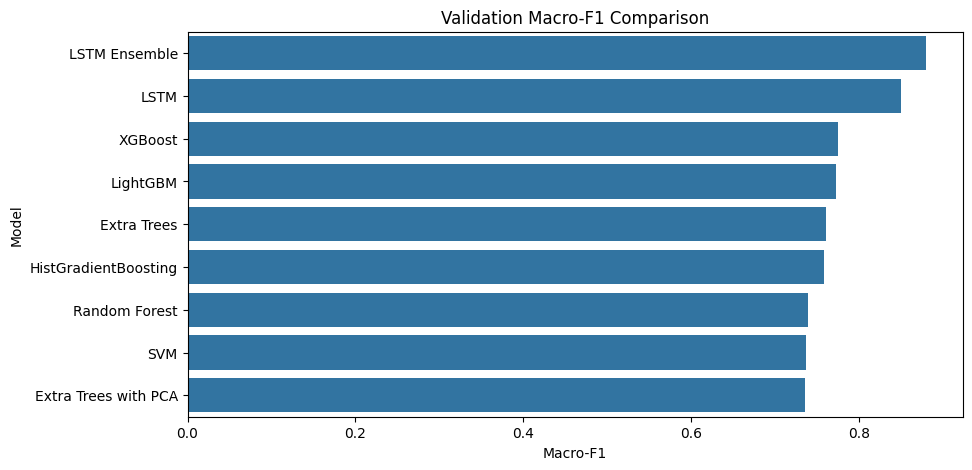

In [ ]:
plt.figure(figsize=(10, 5))
sns.barplot(data=model_results, x="Validation Macro-F1", y="Model")
plt.title("Validation Macro-F1 Comparison")
plt.xlabel("Macro-F1")
plt.ylabel("Model")
plt.show()

In [ ]:
final_seeds = [1, 7, 21]

final_lstm_models = []

for seed in final_seeds:
    print("Training final LSTM seed:", seed)

    model = build_lstm_model(seed)

    early_stop = EarlyStopping(
        monitor="loss",
        patience=8,
        restore_best_weights=True
    )

    model.fit(
        X_seq_scaled,
        y_seq_cat,
        epochs=60,
        batch_size=32,
        callbacks=[early_stop],
        verbose=1
    )

    final_lstm_models.append(model)

print("Final LSTM ensemble trained.")

Training final LSTM seed: 1


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/60
88/88 ━━━━━━━━━━━━━━━━━━━━ 15s 112ms/step - accuracy: 0.2839 - loss: 1.8785
Epoch 2/60
88/88 ━━━━━━━━━━━━━━━━━━━━ 11s 127ms/step - accuracy: 0.4268 - loss: 1.4736
Epoch 3/60
88/88 ━━━━━━━━━━━━━━━━━━━━ 20s 120ms/step - accuracy: 0.5360 - loss: 1.1845
Epoch 4/60
88/88 ━━━━━━━━━━━━━━━━━━━━ 10s 113ms/step - accuracy: 0.6269 - loss: 0.9589
Epoch 5/60
88/88 ━━━━━━━━━━━━━━━━━━━━ 9s 103ms/step - accuracy: 0.7032 - loss: 0.7825
Epoch 6/60
88/88 ━━━━━━━━━━━━━━━━━━━━ 8s 85ms/step - accuracy: 0.7351 - loss: 0.7498
Epoch 7/60
88/88 ━━━━━━━━━━━━━━━━━━━━ 11s 99ms/step - accuracy: 0.7512 - loss: 0.6918
Epoch 8/60
88/88 ━━━━━━━━━━━━━━━━━━━━ 10s 112ms/step - accuracy: 0.7623 - loss: 0.7044
Epoch 9/60
88/88 ━━━━━━━━━━━━━━━━━━━━ 8s 91ms/step - accuracy: 0.7662 - loss: 0.6705
Epoch 10/60
88/88 ━━━━━━━━━━━━━━━━━━━━ 9s 100ms/step - accuracy: 0.8110 - loss: 0.5778
Epoch 11/60
88/88 ━━━━━━━━━━━━━━━━━━━━ 11s 107ms/step - accuracy: 0.8117 - loss: 0.5677
Epoch 12/60
88/88 ━━━━━━━━━━━━━━━━━━━━ 9s 103ms/

In [ ]:
X_test_seq, test_seq_sample_ids = make_sequence_dataset(test_clean)

print("X_test_seq shape:", X_test_seq.shape)

X_test_seq shape: (1438, 100, 14)


In [ ]:
test_num_samples, test_num_timesteps, test_num_signals = X_test_seq.shape

X_test_seq_2d = X_test_seq.reshape(-1, test_num_signals)
X_test_seq_scaled_2d = seq_scaler.transform(X_test_seq_2d)

X_test_seq_scaled = X_test_seq_scaled_2d.reshape(
    test_num_samples,
    test_num_timesteps,
    test_num_signals
)

print("Scaled test sequence shape:", X_test_seq_scaled.shape)

Scaled test sequence shape: (1438, 100, 14)


In [ ]:
test_probabilities = []

for model in final_lstm_models:
    probs = model.predict(X_test_seq_scaled)
    test_probabilities.append(probs)

avg_test_probs = np.mean(test_probabilities, axis=0)

test_preds_zero = np.argmax(avg_test_probs, axis=1)
test_predictions = test_preds_zero + 1

submission_lstm_ensemble = pd.DataFrame({
    "Sample_ID": test_seq_sample_ids,
    "Predicted_Class": test_predictions
})

submission_lstm_ensemble.head()

45/45 ━━━━━━━━━━━━━━━━━━━━ 4s 90ms/step
45/45 ━━━━━━━━━━━━━━━━━━━━ 4s 70ms/step
45/45 ━━━━━━━━━━━━━━━━━━━━ 5s 99ms/step


,Sample_ID,Predicted_Class
0,666,1
1,667,1
2,668,5
3,669,5
4,670,1


In [ ]:
submission_lstm_ensemble["Predicted_Class"].value_counts().sort_index()

,count
Predicted_Class,
1,178
2,158
3,246
4,270
5,317
6,269


In [ ]:
submission_lstm_ensemble.to_csv("submission_lstm_ensemble.csv", index=False)

print("Submission file created.")
print(submission_lstm_ensemble.shape)

assert submission_lstm_ensemble.shape[0] == 1438
assert list(submission_lstm_ensemble.columns) == ["Sample_ID", "Predicted_Class"]
assert submission_lstm_ensemble["Predicted_Class"].between(1, 6).all()

print("LSTM ensemble submission format is correct.")

Submission file created.
(1438, 2)
LSTM ensemble submission format is correct.


In [ ]:
from google.colab import files
files.download("submission_lstm_ensemble.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
tf.random.set_seed(RANDOM_STATE)

lstm_model = Sequential([
    LSTM(64, return_sequences=True, input_shape=(100, 14)),
    Dropout(0.3),

    LSTM(32),
    Dropout(0.3),

    Dense(32, activation="relu"),
    BatchNormalization(),
    Dropout(0.2),

    Dense(6, activation="softmax")
])

lstm_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

lstm_model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 100, 64)        │        20,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 100, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           198 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,022 (132.90 KB)

 Trainable params: 33,958 (132.65 KB)

 Non-trainable params: 64 (256.00 B)

In [ ]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

history = lstm_model.fit(
    X_seq_train,
    y_seq_train,
    validation_data=(X_seq_val, y_seq_val),
    epochs=60,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/60
70/70 ━━━━━━━━━━━━━━━━━━━━ 14s 122ms/step - accuracy: 0.2829 - loss: 1.8622 - val_accuracy: 0.3184 - val_loss: 1.6759
Epoch 2/60
70/70 ━━━━━━━━━━━━━━━━━━━━ 7s 100ms/step - accuracy: 0.4150 - loss: 1.4650 - val_accuracy: 0.3667 - val_loss: 1.5773
Epoch 3/60
70/70 ━━━━━━━━━━━━━━━━━━━━ 8s 119ms/step - accuracy: 0.4731 - loss: 1.2642 - val_accuracy: 0.5635 - val_loss: 1.2974
Epoch 4/60
70/70 ━━━━━━━━━━━━━━━━━━━━ 10s 117ms/step - accuracy: 0.5363 - loss: 1.1050 - val_accuracy: 0.5957 - val_loss: 1.0718
Epoch 5/60
70/70 ━━━━━━━━━━━━━━━━━━━━ 8s 110ms/step - accuracy: 0.5886 - loss: 0.9844 - val_accuracy: 0.6583 - val_loss: 0.8592
Epoch 6/60
70/70 ━━━━━━━━━━━━━━━━━━━━ 8s 120ms/step - accuracy: 0.6374 - loss: 0.9302 - val_accuracy: 0.6887 - val_loss: 0.7940
Epoch 7/60
70/70 ━━━━━━━━━━━━━━━━━━━━ 7s 102ms/step - accuracy: 0.6719 - loss: 0.8403 - val_accuracy: 0.7352 - val_loss: 0.7272
Epoch 8/60
70/70 ━━━━━━━━━━━━━━━━━━━━ 8s 114ms/step - accuracy: 0.7171 - loss: 0.7496 - val_accuracy: 

In [ ]:
lstm_probs = lstm_model.predict(X_seq_val)

lstm_preds_zero = np.argmax(lstm_probs, axis=1)
y_seq_val_zero = np.argmax(y_seq_val, axis=1)

lstm_preds = lstm_preds_zero + 1
y_seq_val_true = y_seq_val_zero + 1

lstm_f1 = f1_score(y_seq_val_true, lstm_preds, average="macro")

model_scores.append({
    "Model": "LSTM",
    "Validation Macro-F1": lstm_f1
})

print("LSTM Macro-F1:", lstm_f1)
print(classification_report(y_seq_val_true, lstm_preds))

18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step
LSTM Macro-F1: 0.8835519422714592
              precision    recall  f1-score   support

           1       0.99      0.99      0.99        76
           2       0.87      0.89      0.88        75
           3       0.82      0.82      0.82        87
           4       0.94      0.82      0.87        98
           5       0.88      0.93      0.90       110
           6       0.82      0.86      0.84       113

    accuracy                           0.88       559
   macro avg       0.89      0.88      0.88       559
weighted avg       0.88      0.88      0.88       559



In [ ]:
print("LSTM Validation Macro-F1:", lstm_f1)

### Model Comparison

We compare all models using validation Macro-F1.

In [ ]:
model_results = pd.DataFrame(model_scores)
model_results = model_results.sort_values("Validation Macro-F1", ascending=False)
model_results

,Model,Validation Macro-F1
7,LSTM,0.883552
5,XGBoost,0.775319
6,LightGBM,0.771910
2,Extra Trees,0.760013
3,HistGradientBoosting,0.757653
0,Random Forest,0.738825
4,SVM,0.736787
1,Extra Trees with PCA,0.735601


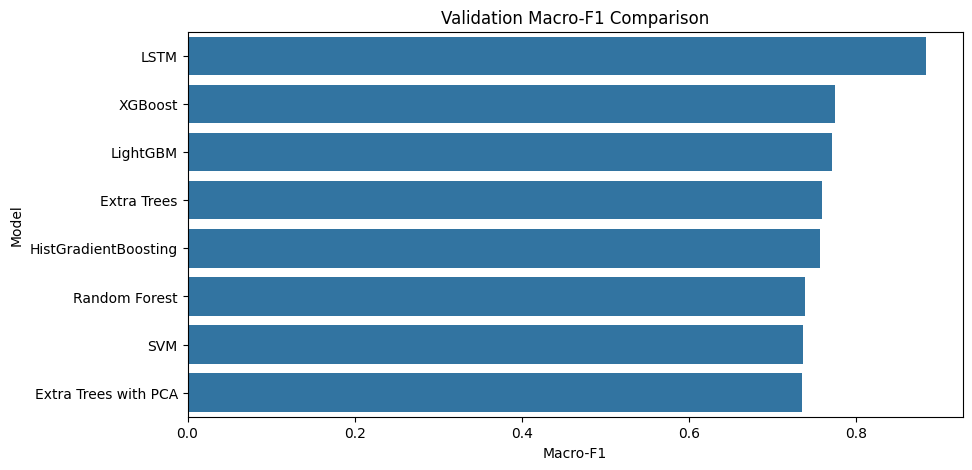

In [ ]:
plt.figure(figsize=(10, 5))
sns.barplot(data=model_results, x="Validation Macro-F1", y="Model")
plt.title("Validation Macro-F1 Comparison")
plt.xlabel("Macro-F1")
plt.ylabel("Model")
plt.show()

XGBoost gives the best validation Macro-F1, so we treat it as the leading model so far.

### Cross-Validation

We use cross-validation to check if the top models generalise well.

### Cross-Validation Runtime Note

We attempted cross-validation for the top boosting models, but full cross-validation was slow on free Colab. To keep the notebook runnable, we use the stratified validation split for model comparison and report the validation Macro-F1 scores.

We train the final LSTM model on all labelled sequence data.

In [ ]:
model_results = pd.DataFrame(model_scores)
model_results = model_results.sort_values("Validation Macro-F1", ascending=False)
model_results

,Model,Validation Macro-F1
4,XGBoost,0.775319
5,LightGBM,0.771910
1,Extra Trees,0.760013
2,HistGradientBoosting,0.757653
0,Random Forest,0.738825
3,SVM,0.736787


The selected model is based on the best validation Macro-F1 while keeping the notebook practical to run on Colab.

### Confusion Matrix

We inspect where the best model makes mistakes.

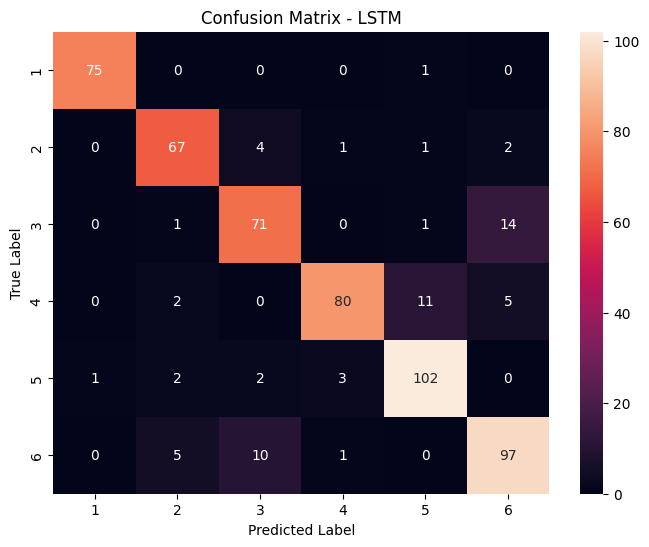

In [ ]:
best_preds = lstm_preds
best_true = y_seq_val_true
best_model_name = "LSTM"

labels = sorted(np.unique(best_true))

cm = confusion_matrix(best_true, best_preds, labels=labels)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", xticklabels=labels, yticklabels=labels)
plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

The confusion matrix shows which classes are easier or harder for the model to separate.

In [71]:
def make_sequence_dataset(sensor_df, labels_df=None):
    sensor_df = sensor_df.copy()
    sensor_df = sensor_df.sort_values(["Sample_ID", "Time_Step"])

    signal_cols = [col for col in sensor_df.columns if col.startswith("Signal")]
    sample_ids = sorted(sensor_df["Sample_ID"].unique())

    X_seq = []

    for sample_id in sample_ids:
        sample = sensor_df[sensor_df["Sample_ID"] == sample_id]
        X_seq.append(sample[signal_cols].values)

    X_seq = np.array(X_seq)

    if labels_df is not None:
        labels_ordered = (
            pd.DataFrame({"Sample_ID": sample_ids})
            .merge(labels_df, on="Sample_ID", how="left")
        )
        y_seq = labels_ordered["class_label"].astype(int).values
        return X_seq, y_seq, sample_ids

    return X_seq, sample_ids

In [72]:
X_seq, y_seq, seq_sample_ids = make_sequence_dataset(data_clean, train)

print("X_seq shape:", X_seq.shape)
print("y_seq shape:", y_seq.shape)

X_seq shape: (2793, 100, 14)
y_seq shape: (2793,)


In [73]:
num_samples, num_timesteps, num_signals = X_seq.shape

seq_scaler = StandardScaler()

X_seq_2d = X_seq.reshape(-1, num_signals)
X_seq_scaled_2d = seq_scaler.fit_transform(X_seq_2d)
X_seq_scaled = X_seq_scaled_2d.reshape(num_samples, num_timesteps, num_signals)

print("Scaled sequence shape:", X_seq_scaled.shape)

Scaled sequence shape: (2793, 100, 14)


In [74]:
y_seq_zero = y_seq - 1
y_seq_cat = to_categorical(y_seq_zero, num_classes=6)

X_seq_train, X_seq_val, y_seq_train, y_seq_val = train_test_split(
    X_seq_scaled,
    y_seq_cat,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_seq_zero
)

print("X_seq_train shape:", X_seq_train.shape)
print("X_seq_val shape:", X_seq_val.shape)
print("y_seq_train shape:", y_seq_train.shape)
print("y_seq_val shape:", y_seq_val.shape)

X_seq_train shape: (2234, 100, 14)
X_seq_val shape: (559, 100, 14)
y_seq_train shape: (2234, 6)
y_seq_val shape: (559, 6)


### CNN-LSTM Classifier

We test a CNN-LSTM model because Conv1D can learn local signal patterns before the LSTM learns the time sequence.

In [75]:
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Input

def build_cnn_lstm_model(seed=RANDOM_STATE):
    tf.random.set_seed(seed)
    np.random.seed(seed)

    model = Sequential([
        Input(shape=(100, 14)),

        Conv1D(filters=64, kernel_size=5, activation="relu", padding="same"),
        BatchNormalization(),
        MaxPooling1D(pool_size=2),
        Dropout(0.2),

        Conv1D(filters=64, kernel_size=3, activation="relu", padding="same"),
        BatchNormalization(),
        Dropout(0.2),

        LSTM(64),
        Dropout(0.3),

        Dense(32, activation="relu"),
        BatchNormalization(),
        Dropout(0.2),

        Dense(6, activation="softmax")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [76]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    MaxPooling1D,
    LSTM,
    Dense,
    Dropout,
    BatchNormalization
)
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import to_categorical

In [77]:


cnn_lstm_model = build_cnn_lstm_model(RANDOM_STATE)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

history_cnn_lstm = cnn_lstm_model.fit(
    X_seq_train,
    y_seq_train,
    validation_data=(X_seq_val, y_seq_val),
    epochs=60,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/60
70/70 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.3299 - loss: 1.8569 - val_accuracy: 0.3900 - val_loss: 1.6344
Epoch 2/60
70/70 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.4427 - loss: 1.4393 - val_accuracy: 0.4293 - val_loss: 1.4953
Epoch 3/60
70/70 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.5278 - loss: 1.2289 - val_accuracy: 0.6029 - val_loss: 1.0625
Epoch 4/60
70/70 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.5882 - loss: 1.0246 - val_accuracy: 0.6816 - val_loss: 0.7641
Epoch 5/60
70/70 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - accuracy: 0.6620 - loss: 0.8886 - val_accuracy: 0.7424 - val_loss: 0.6701
Epoch 6/60
70/70 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.7158 - loss: 0.7756 - val_accuracy: 0.7853 - val_loss: 0.5949
Epoch 7/60
70/70 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.7525 - loss: 0.6654 - val_accuracy: 0.8265 - val_loss: 0.4752
Epoch 8/60
70/70 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.7793 - loss: 0.6195 - val_accuracy: 0.8372 - v

In [78]:
cnn_lstm_probs = cnn_lstm_model.predict(X_seq_val)

cnn_lstm_preds_zero = np.argmax(cnn_lstm_probs, axis=1)
cnn_lstm_true_zero = np.argmax(y_seq_val, axis=1)

cnn_lstm_preds = cnn_lstm_preds_zero + 1
cnn_lstm_true = cnn_lstm_true_zero + 1

cnn_lstm_f1 = f1_score(cnn_lstm_true, cnn_lstm_preds, average="macro")

model_scores.append({
    "Model": "CNN-LSTM",
    "Validation Macro-F1": cnn_lstm_f1
})

print("CNN-LSTM Macro-F1:", cnn_lstm_f1)
print(classification_report(cnn_lstm_true, cnn_lstm_preds))

18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
CNN-LSTM Macro-F1: 0.8854403054103526
              precision    recall  f1-score   support

           1       0.95      1.00      0.97        76
           2       0.80      0.93      0.86        75
           3       0.87      0.79      0.83        87
           4       0.91      0.91      0.91        98
           5       0.89      0.83      0.86       110
           6       0.88      0.88      0.88       113

    accuracy                           0.88       559
   macro avg       0.88      0.89      0.89       559
weighted avg       0.88      0.88      0.88       559



The CNN-LSTM is compared with the LSTM ensemble to see whether local temporal pattern extraction improves performance.

In [79]:
model_results = pd.DataFrame(model_scores)
model_results = model_results.sort_values("Validation Macro-F1", ascending=False)
model_results

,Model,Validation Macro-F1
0,CNN-LSTM,0.88544


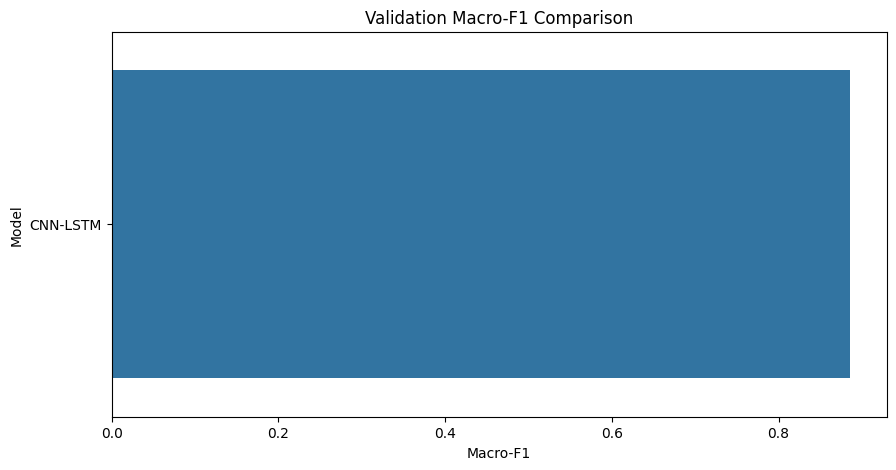

In [80]:
plt.figure(figsize=(10, 5))
sns.barplot(data=model_results, x="Validation Macro-F1", y="Model")
plt.title("Validation Macro-F1 Comparison")
plt.xlabel("Macro-F1")
plt.ylabel("Model")
plt.show()

## Final CNN-LSTM Model Training

We train the final CNN-LSTM model on all labelled sequence data.

In [81]:
final_cnn_lstm_model = build_cnn_lstm_model(RANDOM_STATE)

early_stop = EarlyStopping(
    monitor="loss",
    patience=8,
    restore_best_weights=True
)

final_cnn_lstm_model.fit(
    X_seq_scaled,
    y_seq_cat,
    epochs=60,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

print("Final CNN-LSTM model trained.")

Epoch 1/60
88/88 ━━━━━━━━━━━━━━━━━━━━ 7s 28ms/step - accuracy: 0.3616 - loss: 1.7361
Epoch 2/60
88/88 ━━━━━━━━━━━━━━━━━━━━ 4s 44ms/step - accuracy: 0.4930 - loss: 1.2775
Epoch 3/60
88/88 ━━━━━━━━━━━━━━━━━━━━ 5s 61ms/step - accuracy: 0.6108 - loss: 1.0025
Epoch 4/60
88/88 ━━━━━━━━━━━━━━━━━━━━ 8s 36ms/step - accuracy: 0.6745 - loss: 0.8506
Epoch 5/60
88/88 ━━━━━━━━━━━━━━━━━━━━ 4s 51ms/step - accuracy: 0.7304 - loss: 0.7424
Epoch 6/60
88/88 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - accuracy: 0.7787 - loss: 0.6508
Epoch 7/60
88/88 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.7948 - loss: 0.5786
Epoch 8/60
88/88 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - accuracy: 0.8117 - loss: 0.5598
Epoch 9/60
88/88 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - accuracy: 0.8163 - loss: 0.5479
Epoch 10/60
88/88 ━━━━━━━━━━━━━━━━━━━━ 4s 44ms/step - accuracy: 0.8450 - loss: 0.4661
Epoch 11/60
88/88 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.8532 - loss: 0.4434
Epoch 12/60
88/88 ━━━━━━━━━━━━━━━━━━━━ 4s 44ms/step - accuracy:

## Test Data Processing

We convert the test data into scaled 100-step sequences.

In [82]:
X_test_seq, test_seq_sample_ids = make_sequence_dataset(test_clean)

print("X_test_seq shape:", X_test_seq.shape)

X_test_seq shape: (1438, 100, 14)


In [83]:
test_num_samples, test_num_timesteps, test_num_signals = X_test_seq.shape

X_test_seq_2d = X_test_seq.reshape(-1, test_num_signals)
X_test_seq_scaled_2d = seq_scaler.transform(X_test_seq_2d)

X_test_seq_scaled = X_test_seq_scaled_2d.reshape(
    test_num_samples,
    test_num_timesteps,
    test_num_signals
)

print("Scaled test sequence shape:", X_test_seq_scaled.shape)

Scaled test sequence shape: (1438, 100, 14)


## Kaggle Submission

We use the final CNN-LSTM model to create the Kaggle submission file.

In [84]:
test_cnn_lstm_probs = final_cnn_lstm_model.predict(X_test_seq_scaled)

test_cnn_lstm_preds_zero = np.argmax(test_cnn_lstm_probs, axis=1)
test_cnn_lstm_predictions = test_cnn_lstm_preds_zero + 1

submission_cnn_lstm = pd.DataFrame({
    "Sample_ID": test_seq_sample_ids,
    "Predicted_Class": test_cnn_lstm_predictions
})

submission_cnn_lstm.head()

45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step


,Sample_ID,Predicted_Class
0,666,1
1,667,1
2,668,1
3,669,1
4,670,1


In [85]:
submission_cnn_lstm["Predicted_Class"].value_counts().sort_index()

,count
Predicted_Class,
1,191
2,165
3,237
4,285
5,297
6,263


In [86]:
submission_cnn_lstm.to_csv("submission_cnn_lstm.csv", index=False)

print("Submission file created.")
print(submission_cnn_lstm.shape)

assert submission_cnn_lstm.shape[0] == 1438
assert list(submission_cnn_lstm.columns) == ["Sample_ID", "Predicted_Class"]
assert submission_cnn_lstm["Predicted_Class"].between(1, 6).all()

print("CNN-LSTM submission format is correct.")

Submission file created.
(1438, 2)
CNN-LSTM submission format is correct.


In [87]:
from google.colab import files
files.download("submission_cnn_lstm.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### CNN-LSTM Ensemble

We train CNN-LSTM models with different seeds and average their predictions.

In [88]:
cnn_seeds = [1, 7, 21]

cnn_lstm_seed_scores = []
cnn_lstm_seed_models = []
cnn_lstm_val_probabilities = []

for seed in cnn_seeds:
    print("Training CNN-LSTM seed:", seed)

    model = build_cnn_lstm_model(seed)

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True
    )

    model.fit(
        X_seq_train,
        y_seq_train,
        validation_data=(X_seq_val, y_seq_val),
        epochs=60,
        batch_size=32,
        callbacks=[early_stop],
        verbose=0
    )

    val_probs = model.predict(X_seq_val)
    val_preds_zero = np.argmax(val_probs, axis=1)
    val_true_zero = np.argmax(y_seq_val, axis=1)

    val_preds = val_preds_zero + 1
    val_true = val_true_zero + 1

    score = f1_score(val_true, val_preds, average="macro")

    cnn_lstm_seed_scores.append(score)
    cnn_lstm_seed_models.append(model)
    cnn_lstm_val_probabilities.append(val_probs)

    print("Seed:", seed, "Macro-F1:", score)

print("Mean CNN-LSTM Macro-F1:", np.mean(cnn_lstm_seed_scores))
print("Std CNN-LSTM Macro-F1:", np.std(cnn_lstm_seed_scores))

Training CNN-LSTM seed: 1
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
Seed: 1 Macro-F1: 0.9153802555785222
Training CNN-LSTM seed: 7
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
Seed: 7 Macro-F1: 0.8945621889752416
Training CNN-LSTM seed: 21
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
Seed: 21 Macro-F1: 0.8767302937717351
Mean CNN-LSTM Macro-F1: 0.895557579441833
Std CNN-LSTM Macro-F1: 0.01579447136505391


In [89]:
avg_cnn_val_probs = np.mean(cnn_lstm_val_probabilities, axis=0)

cnn_ensemble_val_preds_zero = np.argmax(avg_cnn_val_probs, axis=1)
cnn_ensemble_val_true_zero = np.argmax(y_seq_val, axis=1)

cnn_ensemble_val_preds = cnn_ensemble_val_preds_zero + 1
cnn_ensemble_val_true = cnn_ensemble_val_true_zero + 1

cnn_lstm_ensemble_f1 = f1_score(
    cnn_ensemble_val_true,
    cnn_ensemble_val_preds,
    average="macro"
)

model_scores.append({
    "Model": "CNN-LSTM Ensemble",
    "Validation Macro-F1": cnn_lstm_ensemble_f1
})

print("CNN-LSTM Ensemble Macro-F1:", cnn_lstm_ensemble_f1)
print(classification_report(cnn_ensemble_val_true, cnn_ensemble_val_preds))

CNN-LSTM Ensemble Macro-F1: 0.912681248010473
              precision    recall  f1-score   support

           1       0.97      1.00      0.99        76
           2       0.93      0.92      0.93        75
           3       0.89      0.80      0.84        87
           4       0.94      0.89      0.91        98
           5       0.90      0.94      0.92       110
           6       0.86      0.92      0.89       113

    accuracy                           0.91       559
   macro avg       0.92      0.91      0.91       559
weighted avg       0.91      0.91      0.91       559



In [90]:
test_probabilities = []

for model in cnn_lstm_seed_models:
    probs = model.predict(X_test_seq_scaled)
    test_probabilities.append(probs)

avg_test_probs = np.mean(test_probabilities, axis=0)

test_preds_zero = np.argmax(avg_test_probs, axis=1)
test_predictions = test_preds_zero + 1

submission_cnn_lstm_ensemble = pd.DataFrame({
    "Sample_ID": test_seq_sample_ids,
    "Predicted_Class": test_predictions
})

submission_cnn_lstm_ensemble["Predicted_Class"].value_counts().sort_index()

45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step


,count
Predicted_Class,
1,195
2,139
3,259
4,275
5,307
6,263


In [91]:
submission_cnn_lstm_ensemble.to_csv("submission_cnn_lstm_ensemble.csv", index=False)

print(submission_cnn_lstm_ensemble.shape)

assert submission_cnn_lstm_ensemble.shape[0] == 1438
assert list(submission_cnn_lstm_ensemble.columns) == ["Sample_ID", "Predicted_Class"]
assert submission_cnn_lstm_ensemble["Predicted_Class"].between(1, 6).all()

print("CNN-LSTM ensemble submission format is correct.")

(1438, 2)
CNN-LSTM ensemble submission format is correct.


In [92]:
from google.colab import files
files.download("submission_cnn_lstm_ensemble.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Blended LSTM and CNN-LSTM Ensemble

We blend the LSTM ensemble and CNN-LSTM ensemble to combine their strengths.

In [95]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping

def build_lstm_model(seed=RANDOM_STATE):
    tf.random.set_seed(seed)
    np.random.seed(seed)

    model = Sequential([
        Input(shape=(100, 14)),

        LSTM(64, return_sequences=True),
        Dropout(0.3),

        LSTM(32),
        Dropout(0.3),

        Dense(32, activation="relu"),
        BatchNormalization(),
        Dropout(0.2),

        Dense(6, activation="softmax")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [96]:
seeds = [1, 7, 21]

lstm_seed_scores = []
lstm_seed_models = []
lstm_val_probabilities = []

for seed in seeds:
    print("Training LSTM seed:", seed)

    model = build_lstm_model(seed)

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True
    )

    model.fit(
        X_seq_train,
        y_seq_train,
        validation_data=(X_seq_val, y_seq_val),
        epochs=60,
        batch_size=32,
        callbacks=[early_stop],
        verbose=0
    )

    val_probs = model.predict(X_seq_val)
    val_preds_zero = np.argmax(val_probs, axis=1)
    val_true_zero = np.argmax(y_seq_val, axis=1)

    val_preds = val_preds_zero + 1
    val_true = val_true_zero + 1

    score = f1_score(val_true, val_preds, average="macro")

    lstm_seed_scores.append(score)
    lstm_seed_models.append(model)
    lstm_val_probabilities.append(val_probs)

    print("Seed:", seed, "Macro-F1:", score)

print("Mean LSTM Macro-F1:", np.mean(lstm_seed_scores))
print("Std LSTM Macro-F1:", np.std(lstm_seed_scores))

Training LSTM seed: 1
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step
Seed: 1 Macro-F1: 0.8480374810293546
Training LSTM seed: 7
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step
Seed: 7 Macro-F1: 0.8528116084143248
Training LSTM seed: 21
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step
Seed: 21 Macro-F1: 0.8672446581584307
Mean LSTM Macro-F1: 0.8560312492007034
Std LSTM Macro-F1: 0.008165107813613966


In [97]:
# Average validation probabilities from each ensemble
avg_lstm_val_probs = np.mean(lstm_val_probabilities, axis=0)
avg_cnn_val_probs = np.mean(cnn_lstm_val_probabilities, axis=0)

blend_results = []

for alpha in np.arange(0.0, 1.1, 0.1):
    # alpha controls how much weight CNN-LSTM gets
    blended_val_probs = (alpha * avg_cnn_val_probs) + ((1 - alpha) * avg_lstm_val_probs)

    blended_preds_zero = np.argmax(blended_val_probs, axis=1)
    blended_true_zero = np.argmax(y_seq_val, axis=1)

    blended_preds = blended_preds_zero + 1
    blended_true = blended_true_zero + 1

    blended_f1 = f1_score(blended_true, blended_preds, average="macro")

    blend_results.append({
        "CNN_LSTM_weight": alpha,
        "LSTM_weight": 1 - alpha,
        "Validation Macro-F1": blended_f1
    })

blend_results_df = pd.DataFrame(blend_results)
blend_results_df.sort_values("Validation Macro-F1", ascending=False)

,CNN_LSTM_weight,LSTM_weight,Validation Macro-F1
7,0.7,0.3,0.925268
8,0.8,0.2,0.920105
5,0.5,0.5,0.919811
6,0.6,0.4,0.916442
9,0.9,0.1,0.912681
10,1.0,0.0,0.912681
4,0.4,0.6,0.910800
3,0.3,0.7,0.890095
0,0.0,1.0,0.884052
2,0.2,0.8,0.883348


In [98]:
best_blend = blend_results_df.sort_values("Validation Macro-F1", ascending=False).iloc[0]

best_alpha = best_blend["CNN_LSTM_weight"]

print("Best CNN-LSTM weight:", best_alpha)
print("Best LSTM weight:", 1 - best_alpha)
print("Best blended validation Macro-F1:", best_blend["Validation Macro-F1"])

Best CNN-LSTM weight: 0.7000000000000001
Best LSTM weight: 0.29999999999999993
Best blended validation Macro-F1: 0.9252681558106346


## Blended Kaggle Submission

We create a final submission by blending LSTM and CNN-LSTM ensemble predictions.

In [100]:
lstm_test_probabilities = []

for model in lstm_seed_models:
    probs = model.predict(X_test_seq_scaled)
    lstm_test_probabilities.append(probs)

avg_lstm_test_probs = np.mean(lstm_test_probabilities, axis=0)

45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step


In [101]:
cnn_test_probabilities = []

for model in cnn_lstm_seed_models:
    probs = model.predict(X_test_seq_scaled)
    cnn_test_probabilities.append(probs)

avg_cnn_test_probs = np.mean(cnn_test_probabilities, axis=0)

45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step


In [102]:
best_alpha = 0.7

blended_test_probs = (best_alpha * avg_cnn_test_probs) + ((1 - best_alpha) * avg_lstm_test_probs)

blended_test_preds_zero = np.argmax(blended_test_probs, axis=1)
blended_test_predictions = blended_test_preds_zero + 1

submission_blended = pd.DataFrame({
    "Sample_ID": test_seq_sample_ids,
    "Predicted_Class": blended_test_predictions
})

submission_blended.head()

,Sample_ID,Predicted_Class
0,666,1
1,667,1
2,668,5
3,669,1
4,670,1


In [103]:
submission_blended["Predicted_Class"].value_counts().sort_index()

,count
Predicted_Class,
1,194
2,146
3,260
4,267
5,317
6,254


In [104]:
submission_blended.to_csv("submission_blended_lstm_cnn.csv", index=False)

print("Submission file created.")
print(submission_blended.shape)

display(submission_blended.head())
display(submission_blended.tail())

assert submission_blended.shape[0] == 1438
assert list(submission_blended.columns) == ["Sample_ID", "Predicted_Class"]
assert submission_blended["Predicted_Class"].between(1, 6).all()

print("Blended submission format is correct.")

Submission file created.
(1438, 2)


,Sample_ID,Predicted_Class
0,666,1
1,667,1
2,668,5
3,669,1
4,670,1


,Sample_ID,Predicted_Class
1433,3883,6
1434,3884,6
1435,3885,6
1436,3886,6
1437,3887,6


Blended submission format is correct.


In [105]:
from google.colab import files
files.download("submission_blended_lstm_cnn.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Final Model Training

We train the selected XGBoost model on all labelled training data.

In [ ]:
final_lstm_model = Sequential([
    LSTM(64, return_sequences=True, input_shape=(100, 14)),
    Dropout(0.3),

    LSTM(32),
    Dropout(0.3),

    Dense(32, activation="relu"),
    BatchNormalization(),
    Dropout(0.2),

    Dense(6, activation="softmax")
])

final_lstm_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

early_stop = EarlyStopping(
    monitor="loss",
    patience=8,
    restore_best_weights=True
)

final_lstm_model.fit(
    X_seq_scaled,
    y_seq_cat,
    epochs=60,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

print("Final LSTM model trained.")

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/60
88/88 ━━━━━━━━━━━━━━━━━━━━ 37s 200ms/step - accuracy: 0.3269 - loss: 1.7702
Epoch 2/60
88/88 ━━━━━━━━━━━━━━━━━━━━ 16s 184ms/step - accuracy: 0.4694 - loss: 1.3436
Epoch 3/60
88/88 ━━━━━━━━━━━━━━━━━━━━ 20s 183ms/step - accuracy: 0.5818 - loss: 1.0458
Epoch 4/60
88/88 ━━━━━━━━━━━━━━━━━━━━ 12s 129ms/step - accuracy: 0.6742 - loss: 0.8650
Epoch 5/60
88/88 ━━━━━━━━━━━━━━━━━━━━ 12s 141ms/step - accuracy: 0.6953 - loss: 0.8307
Epoch 6/60
88/88 ━━━━━━━━━━━━━━━━━━━━ 19s 211ms/step - accuracy: 0.7433 - loss: 0.7238
Epoch 7/60
88/88 ━━━━━━━━━━━━━━━━━━━━ 17s 166ms/step - accuracy: 0.7479 - loss: 0.7244
Epoch 8/60
88/88 ━━━━━━━━━━━━━━━━━━━━ 12s 139ms/step - accuracy: 0.7641 - loss: 0.6558
Epoch 9/60
88/88 ━━━━━━━━━━━━━━━━━━━━ 8s 87ms/step - accuracy: 0.7755 - loss: 0.6610
Epoch 10/60
88/88 ━━━━━━━━━━━━━━━━━━━━ 10s 110ms/step - accuracy: 0.8031 - loss: 0.5772
Epoch 11/60
88/88 ━━━━━━━━━━━━━━━━━━━━ 10s 109ms/step - accuracy: 0.8274 - loss: 0.5210
Epoch 12/60
88/88 ━━━━━━━━━━━━━━━━━━━━ 9s 9

## Test Data Processing

We apply the same feature engineering steps to the test data.

In [ ]:
X_test_seq, test_seq_sample_ids = make_sequence_dataset(test_clean)

print("X_test_seq shape:", X_test_seq.shape)

X_test_seq shape: (1438, 100, 14)


In [ ]:
test_num_samples, test_num_timesteps, test_num_signals = X_test_seq.shape

X_test_seq_2d = X_test_seq.reshape(-1, test_num_signals)
X_test_seq_scaled_2d = seq_scaler.transform(X_test_seq_2d)
X_test_seq_scaled = X_test_seq_scaled_2d.reshape(
    test_num_samples,
    test_num_timesteps,
    test_num_signals
)

print("Scaled test sequence shape:", X_test_seq_scaled.shape)

Scaled test sequence shape: (1438, 100, 14)


The test data now has the same engineered feature structure as the training data.

## Kaggle Submission

We predict labels for the unseen test set and save the submission file.

In [ ]:
test_lstm_probs = final_lstm_model.predict(X_test_seq_scaled)

test_lstm_preds_zero = np.argmax(test_lstm_probs, axis=1)
test_lstm_predictions = test_lstm_preds_zero + 1

submission_lstm = pd.DataFrame({
    "Sample_ID": test_seq_sample_ids,
    "Predicted_Class": test_lstm_predictions
})

submission_lstm.head()

45/45 ━━━━━━━━━━━━━━━━━━━━ 7s 94ms/step


,Sample_ID,Predicted_Class
0,666,1
1,667,1
2,668,1
3,669,1
4,670,1


In [ ]:
submission_lstm.to_csv("submission_lstm.csv", index=False)

print("Submission file created.")
print(submission_lstm.shape)

assert submission_lstm.shape[0] == 1438
assert list(submission_lstm.columns) == ["Sample_ID", "Predicted_Class"]
assert submission_lstm["Predicted_Class"].between(1, 6).all()

print("LSTM submission format is correct.")

Submission file created.
(1438, 2)


,Sample_ID,Predicted_Class
0,666,1
1,667,1
2,668,5
3,669,5
4,670,1


In [ ]:
submission_lstm["Predicted_Class"].value_counts().sort_index()

,count
Predicted_Class,
1,186
2,158
3,223
4,332
5,269
6,270


In [ ]:
submission_lstm.to_csv("submission_lstm.csv", index=False)

from google.colab import files
files.download("submission_lstm.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

The submission file contains one predicted class label for each test `Sample_ID`.